<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/QP-day2/QP_Day2_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> <a href="https://kaggle.com/kernels/welcome?src=https://github.com/imguru-mooc/AI_CAMPUS/blob/main/QP-day2/QP_Day2_lecture.ipynb" target="_blank"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" alt="Open In Kaggle"/></a>

# Quantization·Pruning Day 2 — ONNX Runtime PTQ: 학습 없이 INT8 로

**온디바이스 AI · Quantization·Pruning 2/6 · 11/17(화)** · Google Colab 또는 Kaggle (하드웨어 없음) · ONNX · ONNX Runtime

어제는 NumPy 로 scale · zero_point 를 직접 계산했습니다. 오늘은 **ONNX Runtime 의 양자화 도구**로 학습된 모델 전체를 INT8 로 바꿉니다 — 재학습 없이 바꾸는 방법이 **PTQ (Post-Training Quantization)** 입니다.

오늘의 모델은 VB Day 2 에서 학습한 **ResNet-20 (CIFAR-10)** 입니다. 정확도를 바로 잴 수 있도록 CIFAR-10 테스트 이미지 2,500장을 **보정용 500장 · 평가용 2,000장**으로 나눠 두었습니다 (서로 겹치지 않음).

> **PyTorch → ONNX** → **전처리** → **보정(calibration)** → **INT8 ONNX** → **정확도 · 크기 · 속도 기록**

오늘의 목표

1. **dynamic** 과 **static** PTQ 의 차이를 말하고, 각각 `quantize_dynamic` · `quantize_static` 으로 만들 수 있다.
2. `quant_pre_process` 와 **BatchNorm folding** 이 양자화 전에 하는 일을 설명할 수 있다.
3. `CalibrationDataReader` 를 직접 작성하고, 보정 데이터가 정확도에 주는 영향을 실험할 수 있다.
4. ONNX 파일 안의 scale · zero_point 를 꺼내 **Day 1 `my_quant.py` 로 검산**할 수 있다.
5. **QDQ** 와 **QOperator** 형식, **U8 / S8** 활성값의 차이를 그래프와 속도로 비교할 수 있다.
6. **MinMax · Entropy · Percentile** 보정과 per-channel 설정을 비교하고, 결과를 `qp_baseline.csv` 에 기록할 수 있다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | PTQ 개관 — ResNet-20 을 ONNX 로, 평가 함수 만들기 |
| 2 | 10:00–10:50 | Dynamic 양자화 — 한 줄로 INT8, 그런데 왜 느릴까 |
| 3 | 11:00–11:50 | 양자화 전처리 — BatchNorm folding · quant_pre_process |
| 4 | 13:00–13:50 | Static 양자화 — CalibrationDataReader · scale 검산 |
| 5 | 14:00–14:50 | QDQ vs QOperator — 그래프 모양 · U8 / S8 |
| 6 | 15:00–15:50 | Calibration 방법 비교 — MinMax · Entropy · Percentile |
| 7 | 16:00–16:50 | 성능 측정 — 크기 · 정확도 · 지연 시간 · qp_baseline.csv |
| 8 | 17:00–17:50 | 미니 프로젝트 — 최적 PTQ 설정 찾기 · 채점 |

**노트북 사용법**

1. 아래 **0. 실행 환경 준비**대로 Colab 또는 Kaggle 에서 내 사본을 만들어 작업합니다. 오늘은 **CPU** 로 모두 실행됩니다 (GPU 불필요).
2. **✍️ 직접 구현** 셀은 **교시마다 2문제**입니다. 문제를 보고 `# TODO` 부분을 직접 코드로 작성합니다. 실행 후 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다. 막히면 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다.
3. **🔒 정답 보기** 셀은 **실습마다 다른 잠금 코드**로 잠겨 있습니다. 강사가 그 실습의 코드를 알려 주면 셀을 실행해 입력합니다. 정답을 연 기록은 8교시 채점 셀 결과에 함께 표시됩니다 — 먼저 힌트로 끝까지 시도해 보세요.
4. **▶ 예제 (제공 코드)** 셀은 직접 구현이 아닙니다 — 그대로 실행하고 출력 · 해설을 읽습니다. 뒤 교시가 이 셀의 함수 · 변수를 쓰므로 **건너뛰지 말고 실행**하세요.
5. 매 교시는 **보기 → 직접 구현 → 바꿔보기** 순서입니다. `🔁 바꿔보기` 셀은 숫자 하나만 바꿔 결과를 관찰합니다.
6. 8교시 미니 프로젝트는 이 노트북 끝에 있습니다 (정답 셀 없음). 채점 셀 결과가 보이는 상태로 제출합니다.
7. 수업이 끝나면 **Day 2 복습 퀴즈**(HTML)를 풀고 제출합니다 — 노트북 맨 끝에 링크가 있습니다.

## 0. 실행 환경 준비 — Colab 또는 Kaggle

| 단계 | Google Colab | Kaggle |
|---|---|---|
| 열기 | 맨 위 **Open in Colab** 배지 | 맨 위 **Open in Kaggle** 배지 (또는 *File → Import Notebook* 에서 GitHub 주소 붙여넣기) |
| 내 사본 | *파일 → Drive에 사본 저장* | 열면 내 계정의 노트북으로 만들어짐 · 작업 후 **Save Version** |
| 인터넷 | 기본으로 켜져 있음 | 오른쪽 패널 *Session options* → **Internet On** (처음 한 번 **전화번호 인증** 필요) — `onnxruntime` 설치와 데이터 내려받기에 필요 |
| 가속기 | 오늘은 CPU 그대로 | 오늘은 **None** (Day 3 부터 **GPU T4 x2**) |
| 생성형 AI | 이 노트북은 **생성형 AI 기능이 숨겨진 상태**로 배포됩니다. **다시 켜지 마세요** — 제출 파일에서 이 설정을 확인합니다. *도구 → 설정 → AI 지원* 의 **AI 기반 인라인 완성 표시** 도 꺼 두세요 | 노트북 안에 AI 자동 완성 없음 |
| 숨김 셀 | 🔒 · 🖼 · 💡 셀은 코드가 접혀 있음 | 코드가 보이지만 그대로 실행하면 됨 (정답은 잠금 코드 없이는 보이지 않음) |

> 아래 **환경 셀**을 실행하면 `실행 환경`, 인터넷 연결, 설치한 `onnxruntime` 버전이 출력됩니다.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/animation.html) |
| 📝 Day 2 복습 퀴즈 (수업이 끝난 뒤, 24문항) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/review_quiz.html](https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/review_quiz.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/QP_Day2.pdf](https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/QP_Day2.pdf) |

**오늘의 데이터 · 모델** — VB Day 2 의 **ResNet-20** 학습 가중치 (`resnet20_cifar10.pt`), CIFAR-10 테스트 이미지 **보정용 500장** (`cifar_calib.npz`, 클래스당 50장) · **평가용 2,000장** (`cifar_eval.npz`, 클래스당 200장), Day 1 의 `my_quant.py`. 모두 노트북이 자동으로 내려받습니다.

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, sys, copy, time, shutil, urllib.request, warnings, inspect, contextlib, io, importlib, importlib.util, subprocess
from collections import Counter

# ── 실행 환경 감지 (Colab · Kaggle · 내 PC) ──
try:
    import google.colab  # noqa: F401
    PLATFORM = "Colab"
except ImportError:
    PLATFORM = "Kaggle" if ("KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.isdir("/kaggle/working")) else "Local"
if PLATFORM == "Kaggle":
    os.chdir("/kaggle/working")

def _online(url="https://raw.githubusercontent.com", timeout=5):
    try:
        urllib.request.urlopen(url, timeout=timeout); return True
    except Exception:
        return False
ONLINE = _online()

# ── onnx · onnxruntime 설치 (없을 때만) ──
_need = [p for p in ["onnx", "onnxruntime"] if importlib.util.find_spec(p) is None]
if _need:
    print("설치:", _need)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_need], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import onnx, onnxruntime as ort
from onnx import numpy_helper
from onnxruntime.quantization import (quantize_dynamic, quantize_static, CalibrationDataReader,
                                      QuantFormat, QuantType, CalibrationMethod)
from onnxruntime.quantization.shape_inference import quant_pre_process

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 140)
torch.manual_seed(0); np.random.seed(0)
BASE = "https://imguru-mooc.github.io/AI_CAMPUS/QP-day2"
RAW = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day2"
EXPORT_KW = {"dynamo": False} if "dynamo" in inspect.signature(torch.onnx.export).parameters else {}
CPU = ["CPUExecutionProvider"]
CLASSES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
MEAN = np.array((0.4914, 0.4822, 0.4465), np.float32)
STD = np.array((0.2470, 0.2435, 0.2616), np.float32)

print(f"실행 환경: {PLATFORM} | 작업 폴더: {os.getcwd()} | 인터넷: {'연결됨' if ONLINE else '끊김'} | GPU: {torch.cuda.is_available()}")
print(f"PyTorch {torch.__version__} | onnx {onnx.__version__} | onnxruntime {ort.__version__}")
if not ONLINE:
    print("⚠️ 인터넷이 꺼져 있습니다." + (" Kaggle: Session options → Internet 을 켜고 이 셀부터 다시 실행하세요." if PLATFORM == "Kaggle" else ""))

def fetch(name):
    """data/<name> 이 없으면 강의 자료 서버(GitHub Pages → GitHub 원본 순)에서 내려받는다"""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        for url in [f"{BASE}/data/{name}", f"{RAW}/data/{name}"]:
            try:
                urllib.request.urlretrieve(url, path)
                break
            except Exception as e:
                if os.path.exists(path): os.remove(path)
                print("내려받기 실패:", url, "→", e)
        else:
            raise FileNotFoundError(f"{name} 을 내려받지 못했습니다. 인터넷 연결을 확인하거나 강사에게 받은 파일을 data 폴더에 올리세요.")
    return path

@contextlib.contextmanager
def quiet():
    """양자화 도구가 출력하는 긴 로그를 숨긴다 — with quiet(): quantize_static(...)"""
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        yield

def size_kb(path):
    return os.path.getsize(path) / 1024

import hashlib, base64, datetime
_HINT_N = {}
def show_hint(no, blob):
    # 💡 실행할 때마다 힌트를 하나씩 더 보여 준다
    hints = base64.b64decode(blob).decode("utf-8").split("\x1e")
    k = min(_HINT_N.get(no, 0) + 1, len(hints)); _HINT_N[no] = k
    for i in range(k):
        print(f"💡 힌트 {i + 1}/{len(hints)} — {hints[i]}")
    print("(다시 실행하면 다음 힌트)" if k < len(hints) else "(힌트를 모두 봤습니다 — 이제 직접 구현해 보세요)")

def show_answer(no, blob):
    # 🔒 잠금된 정답 보기 — 강사가 알려 준 '실습별' 잠금 코드가 있어야 열린다
    raw = base64.b64decode(blob); tag, body = raw[:8], raw[8:]
    for _ in range(2):
        code = input(f"🔒 실습 {no} 잠금 코드: ").strip().upper()
        ks, i = b"", 0
        while len(ks) < len(body):
            ks += hashlib.sha256(f"{code}|qp-day2|{no}|{i}".encode()).digest(); i += 1
        plain = bytes(a ^ b for a, b in zip(body, ks))
        if hashlib.sha256(plain).digest()[:8] == tag:
            with open(".qp_answer_log", "a") as f:
                f.write(f"{no}\t{datetime.datetime.now():%H:%M}\n")
            print(plain.decode("utf-8")); return
        if not code: break
    print("❌ 잠금 코드가 맞지 않습니다. 강사가 이 실습의 코드를 공개하면 다시 실행하세요.")

In [ ]:
# ▶ 데이터 · 모델 준비 — 보정용 500장 · 평가용 2,000장, Day 1 의 my_quant.py
cal, ev = np.load(fetch("cifar_calib.npz")), np.load(fetch("cifar_eval.npz"))
if not os.path.exists("my_quant.py"):                 # Day 1 에서 만든 파일을 올렸다면 그것을 쓴다
    shutil.copy(fetch("my_quant.py"), "my_quant.py")
import my_quant

def preprocess(images):
    """uint8 (N, 32, 32, 3) → 정규화한 float32 (N, 3, 32, 32) — VB Day 2 와 같은 전처리"""
    x = images.astype(np.float32) / 255.0
    return ((x - MEAN) / STD).transpose(0, 3, 1, 2).copy()

X_cal, y_cal = preprocess(cal["images"]), cal["labels"]
X_ev, y_ev = preprocess(ev["images"]), ev["labels"]
print("보정용", X_cal.shape, "| 평가용", X_ev.shape, "| 평가용 클래스별 장수", np.bincount(y_ev))

fig, ax = plt.subplots(1, 10, figsize=(13, 1.6))
for k in range(10):
    ax[k].imshow(ev["images"][np.where(y_ev == k)[0][0]]); ax[k].set_title(CLASSES[k], fontsize=9); ax[k].axis("off")
plt.show()

## 1교시 — PTQ 개관: ResNet-20 을 ONNX 로, 평가 함수 만들기

### 이번 과목의 6일 중 오늘

| 일차 | 날짜 | 계단 | 만드는 것 |
|---|---|---|---|
| Day 1 | 11/16(월) | 양자화의 수학 | `my_quant.py`, 손으로 만든 INT8 CNN |
| **Day 2** | 11/17(화) | **ONNX Runtime PTQ** | `rn20_int8.onnx`, calibration 비교, `qp_baseline.csv` |
| Day 3 | 11/18(수) | PTQ 디버깅 · TensorRT INT8 | layer 별 오차, YOLOv8n INT8 엔진 · mAP |
| Day 4 | 11/19(목) | QAT | fake quantization · STE |
| Day 5 | 11/20(금) | Pruning | structured pruning · fine-tuning |
| Day 6 | 11/23(월) | 통합 경량화 | 침입 감지 파이프라인 |

### PTQ 두 가지

| | Dynamic 양자화 | Static 양자화 |
|---|---|---|
| weight | 미리 INT8 | 미리 INT8 |
| 활성값 scale | **실행할 때마다** 그 입력의 min · max 로 계산 | **보정 데이터**로 미리 정해 파일에 저장 |
| 준비물 | 모델만 | 모델 + 보정 데이터 (수백 장) |
| 잘 맞는 모델 | MatMul · Linear 위주 (LSTM · Transformer) | **Conv 위주 (CNN)** |
| ORT 함수 | `quantize_dynamic` | `quantize_static` + `CalibrationDataReader` |

> 🎬 **애니메이션** [D2-1 PTQ 지도](https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/animation.html#d2-1)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

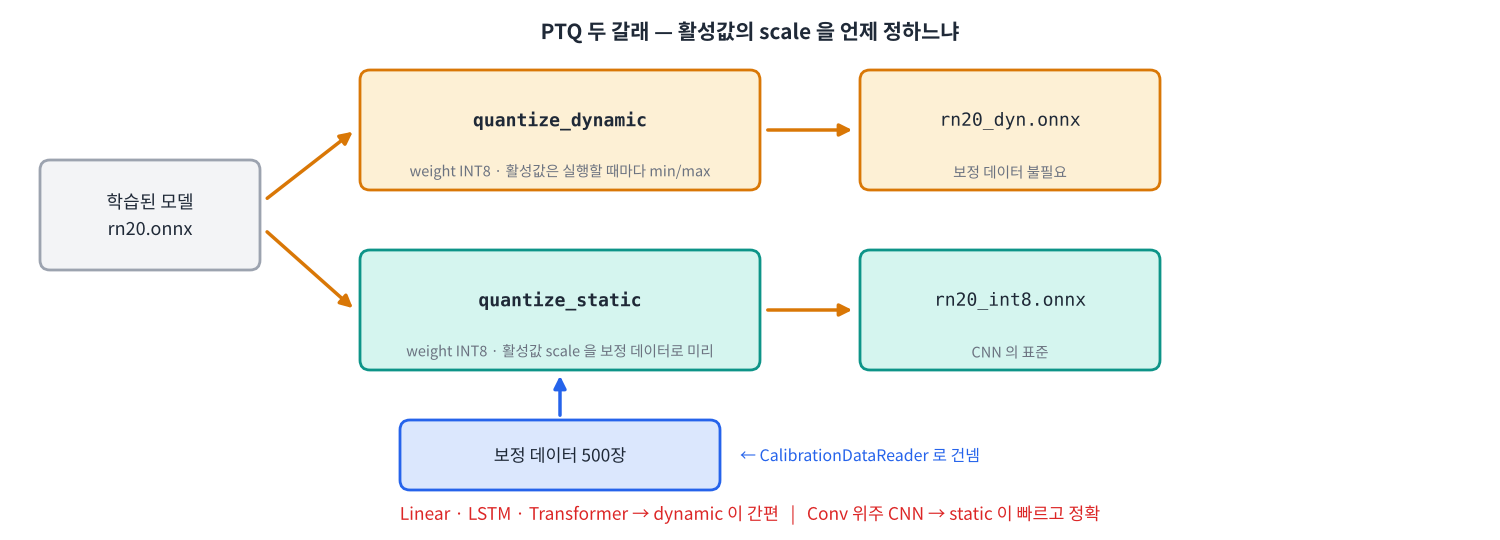

In [ ]:
#@title 🖼 그림 — PTQ 두 갈래 — dynamic 은 실행 중에, static 은 보정 데이터로 미리 scale 을 정한다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day2/img/f1_ptq.png", embed=True, width=860))

먼저 VB Day 2 의 ResNet-20 구조를 다시 만들고 학습된 가중치를 불러옵니다.

In [ ]:
class BasicBlock(nn.Module):                      # VB Day 2 와 같은 구조
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, stride=1, padding=1, bias=False); self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = (nn.Sequential(nn.Conv2d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm2d(cout))
                         if stride != 1 or cin != cout else nn.Identity())
        self.residual = True

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))

class ResNet(nn.Module):
    def __init__(self, n=3, n_cls=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        self.layer1 = nn.Sequential(*[BasicBlock(16, 16) for _ in range(n)])
        self.layer2 = nn.Sequential(BasicBlock(16, 32, 2), *[BasicBlock(32, 32) for _ in range(n - 1)])
        self.layer3 = nn.Sequential(BasicBlock(32, 64, 2), *[BasicBlock(64, 64) for _ in range(n - 1)])
        self.pool = nn.AdaptiveAvgPool2d(1); self.fc = nn.Linear(64, n_cls)

    def forward(self, x):
        x = self.layer3(self.layer2(self.layer1(self.stem(x))))
        return self.fc(self.pool(x).flatten(1))

model = ResNet()
model.load_state_dict(torch.load(fetch("resnet20_cifar10.pt"), map_location="cpu"))
model.eval()
print("ResNet-20 파라미터:", f"{sum(p.numel() for p in model.parameters()):,}")

**▶ 예제 1-A (제공 코드 — 실행만)** PyTorch 모델의 평가용 2,000장 정확도 `torch_acc` 를 구합니다. 이 값이 오늘 모든 INT8 모델의 **기준(FP32)** 입니다.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 1-A — 제공 코드 (그대로 실행)
with torch.no_grad():
    logits = model(torch.from_numpy(X_ev)).numpy()
torch_acc = float((logits.argmax(1) == y_ev).mean())
print(f"PyTorch FP32 정확도 {torch_acc:.4f}")

In [ ]:
assert abs(torch_acc - 0.846) < 0.003; print("✅ 기준 정확도", torch_acc)

> 💡 **예제 1-A 해설** — model.eval() 상태에서 torch.no_grad() 로 2,000장을 한 번에 넣고, argmax 가 정답과 같은 비율을 셉니다. 평가용 2,000장에서 84.6% 입니다. VB Day 2 에서 잰 전체 테스트 정확도와는 쓰는 이미지가 달라 숫자가 조금 다를 수 있습니다.

**✍️ 직접 구현 1-1** 모델을 `rn20.onnx` 로 내보내세요. 입력 이름 `input`, 출력 이름 `logits`, **배치 크기를 바꿀 수 있게** (`dynamic_axes`), opset 17 로 내보냅니다. 그리고 ONNX Runtime 출력과 PyTorch 출력의 최대 차이 `export_diff` 를 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 1-1 — 실행할 때마다 하나씩
show_hint("1-1", "YHRvcmNoLm9ubnguZXhwb3J0KG1vZGVsLCDsmIjsi5zsnoXroKUsIO2MjOydvOydtOumhCwgaW5wdXRfbmFtZXM9Wy4uLl0sIG91dHB1dF9uYW1lcz1bLi4uXSwgZHluYW1pY19heGVzPS4uLiwgb3BzZXRfdmVyc2lvbj0xNywgKipFWFBPUlRfS1cpYB7smIjsi5wg7J6F66Cl7J2AIGB0b3JjaC56ZXJvcygxLCAzLCAzMiwgMzIpYC4eYGR5bmFtaWNfYXhlcz17ImlucHV0IjogezA6ICJOIn0sICJsb2dpdHMiOiB7MDogIk4ifX1gIOKAlCAw67KIIOy2lSjrsLDsuZgp7J2EIOqwgOuzgOycvOuhnC4e67mE6rWQOiBPTk5YIFJ1bnRpbWUg7IS47IWY7Jy866GcIGBYX2V2Wzo4XWAg7J2EIOyLpO2Wie2VtCBgbG9naXRzWzo4XWAg6rO87J2YIOy1nOuMgCDsoIjrjIAg7LCo7J20Lg==")

In [ ]:
# ✍️ 직접 구현 1-1 — rn20.onnx 내보내기, sess (InferenceSession), export_diff (float)
# TODO: torch.onnx.export(...)
sess = None         # TODO
export_diff = None  # TODO

print(f"rn20.onnx {size_kb('rn20.onnx'):.0f} KB | 입력 {sess.get_inputs()[0].shape} | PyTorch 와 최대 차이 {export_diff:.2e}")

In [ ]:
assert sess.get_inputs()[0].name == "input" and sess.get_inputs()[0].shape[0] == "N" and export_diff < 1e-4
print("✅ 배치 크기 가변 · 출력 일치")

In [ ]:
#@title 🔒 정답 보기 1-1 — 강사가 알려 준 실습 1-1 잠금 코드를 입력하세요
show_answer("1-1", (
    "bvRhUlerqiNsBVDTVvjUowwsEzPL2gx9civB1/gYVKdPxHsh2IbJP2Loa0FuDKlFVtwjtGLhvtLE9XRBU3auGQVe"
    "qIh6H/ClAZez/zD2p7lMf0z+4T1BEjsyuw4tEdAJOGfD/mZsMtHZnhMyCP4F086LZrRrg+Km8zTtEhrHIL2XZB5C"
    "34DrE5S//0eN2XgnGj98JwyLvKg5Z/F12QpjYlF9Fq4Mxve7UePOiJW6+/qWB73VfYJV44ShdLeSSTs8789HLDFP"
    "MNiPGwOcH3tmlsY5JKshU/HayFVMJm/bcWcbaAf3KhE4TL5p7qqi5XIUsxCMhTPfvRcAQPW2caIYaLadTTVxMj1b"
    "Gb2tbgSJdXMdKCgIKJertmFqdSU8AeDDWrnt0+l2g1AiRPFMF6ZPegjhe6HkYeyiHWM0iMe/0aX9Ys9/MuxSlxH1"
    "R3UJmQ2xp/aQinHTBnAnKFfo9OBHt28wlEX0x3Rm1ea53LwGEeLssUGE1c8jLjVsUwa/8SLcTM8BViQzRi+8GIyR"
    "GaaBdUs+P47wN2KefmmywWvURHCKHft9gY/HL+ylU9EW2ZnLCTrxTwvDqb5gej1MoDffN5qJfFWJGDwM61FlopxP"
    "B59fsai/N3MxsJpNtXnNS0RVZpMdgMtTZnAkoKxRckNR3NVZjp6cKO1NMNO1pfrJAEmLz8lhbHRjccWWuF3VSEer"
    "D/Tiu8uUR18D8l0RwLCD/jiKKrdShZE+EXWf4rYHnDGAzKzrCes6Hxc4hajZpYy58YR6qAKznDcB7TvI16N6IAwH"
    "NJ3ZUieWNGVczrmDOMX7P+doAieXqMUn2VA/j2AZeaffLUWFC8zVuJBtLKrkOGLEa2ZJmnBR39Tls76hQEWmnQWM"
    "PRMVc+adGq3oFckXMu3u9JJJOE0MfiVHPOXC0l6ejpOzidcycHfou5WhD/ZkQKhIVn3x5sum4aRQuKmRHrBc5CNF"
    "xqwzCqBYeNcsHM3ejEjp54+5ykHj3rZqmix4b0PxSMsvZRbjlFWRu82/oV9foWjqNZJ/ZKh4bgcNmUW5cla8po2k"
    "7izLLbWAsbAMpwFvZPUoauZQ779Wji4g/wKdw8wBohZNsXAokb8VxMj/QPs="
))


**✍️ 직접 구현 1-2** ONNX 파일의 정확도를 재는 함수 `ort_acc(path, X, y, bs=250)` 를 만드세요. 배치 단위로 나눠 실행하고 정확도(0~1)를 돌려줍니다. **오늘 모든 INT8 모델을 이 함수로 평가합니다.**

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 1-2 — 실행할 때마다 하나씩
show_hint("1-2", "YG9ydC5JbmZlcmVuY2VTZXNzaW9uKHBhdGgsIHByb3ZpZGVycz1DUFUpYCDroZwg7IS47IWY7J2EIO2VnCDrsogg66eM65Ot64uI64ukLh5gZm9yIGkgaW4gcmFuZ2UoMCwgbGVuKFgpLCBicylgIOuhnCDsnpjrnbwgYHMucnVuKE5vbmUsIHsiaW5wdXQiOiBYW2k6aSArIGJzXX0pWzBdYCDsnZggYXJnbWF4IOulvCDrqqjsnY3ri4jri6QuHmBucC5jb25jYXRlbmF0ZWAg66GcIOydtOyWtCDrtpnsl6wg7KCV64u16rO8IOu5hOq1kC4gWCDCtyB5IOulvCDsg53rnrXtlZjrqbQgWF9ldiDCtyB5X2V2IOulvCDsk7Dqsowg7ZWY7IS47JqULg==")

In [ ]:
# ✍️ 직접 구현 1-2 — ONNX 모델 정확도 함수
def ort_acc(path, X=None, y=None, bs=250):
    # TODO
    pass

fp32_acc = ort_acc("rn20.onnx")
print(f"ONNX FP32 정확도 {fp32_acc:.4f}")

In [ ]:
assert abs(fp32_acc - torch_acc) <= 0.001 and ort_acc("rn20.onnx", X_ev[:250], y_ev[:250], bs=50) == float((logits[:250].argmax(1) == y_ev[:250]).mean())
print("✅ ONNX 정확도 = PyTorch 정확도")

In [ ]:
#@title 🔒 정답 보기 1-2 — 강사가 알려 준 실습 1-2 잠금 코드를 입력하세요
show_answer("1-2", (
    "0mpxoPnr34VisYFb/Nd1GpG5E+sXpQoSDP+spmqSdjK7GBDFJZiL35cgFRFBVdCpbj5t+sRmgMlNvcAp7IV0+6VJ"
    "dC6LsOsl/M+DJKkUMTs0LYHB5PEJC32yL4KsozdAAn/8M0p5KCYg+XSUM65hZcgT2r5aNRudN/OMdxYCayy3i0q3"
    "gKNBjZKIBPf1kQSIXYroQOaqBSWCvZLognERjj1cMcyY5QlOWN8yKH9rjbQJ4BT4hX8TXEZDyD48SA615/f3Iovy"
    "2VEQz9eqQhz5fGGUVGexYs/TsrplTIjYEdWQZcU5IBybLfbx+Jij4Tg5RVRBDoH7CvOvLAIcTK66Am3WtczC/2aL"
    "kZBNf2O97XS2EaT0knw7SIXHxlYw3zgdH9smimYtKYd8h/l9LKYXnQBzNEAK7TyoseQS4xA6L8FsACKetI5DaHtW"
    "ASm2EVTief7ShAXci30gg6ffSwfbPc3USuk+TBwIuGM2l3cH6C10rMExMAOXQia2NsfUYH3hAfBXgcfOoBm9zlqD"
    "P17WIbtglfKy1NIlCdQlbPga7iN1aVTeqe+6q6N7LCrz1vzyDYMSV8yDeOCAO7ZQhdh9XBE7lq/VcJBQnAu07Bvx"
    "hgciQ4kqok4DYu1lMQYGTe8yoI7xJRmRhRRYx25UBb/aafMYSp4PZGnhEApoO2OvXDEII3wWUvt3Q5cB3Jr81Yc4"
    "nxyKw5PIRuS62Y85GnJ4SiKEA6gjUFL73iRZy33IG/JBS5CSn0tyL8huspTEQMi/kKhshBLgB9dzbdB3ZWFXVELJ"
    "5w+BFrpZWjhBQem44nH3sIqw4QJmqXocQNAU+H/DpUKAjHt/JRj6PjtqysZu8neFQBnSM0REN7P6n6JlyTNEAwBs"
    "PTaoccw7BlUmR0K3GKIZ+p5FWPA1xyu2YgQI5gaMkeCKi/2aiA=="
))


#### 📌 1교시 정리

- PTQ = 학습 없이 양자화. **dynamic** (실행 중 scale) vs **static** (보정 데이터로 미리 scale).
- 기준을 먼저 잡는다: PyTorch 정확도 = ONNX 정확도 = **0.846** (평가용 2,000장).
- `ort_acc()` 는 오늘 모든 모델을 같은 조건으로 평가하는 도구.

## 2교시 — Dynamic 양자화: 한 줄로 INT8, 그런데 왜 느릴까

`quantize_dynamic` 은 weight 만 미리 INT8 로 바꾸고, 활성값은 **실행할 때마다** 그 입력의 min · max 를 재서 양자화합니다. 보정 데이터가 필요 없어 가장 쉽습니다.

> 🎬 **애니메이션** [D2-2 dynamic 양자화와 bench](https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/animation.html#d2-2)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

**✍️ 직접 구현 2-1** `rn20.onnx` 를 dynamic 양자화해 `rn20_dyn.onnx` 로 저장하고 (weight 는 `QuantType.QInt8`), 두 파일 크기 `kb_fp32` · `kb_dyn` 과 정확도 `acc_dyn` 을 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 2-1 — 실행할 때마다 하나씩
show_hint("2-1", "YHF1YW50aXplX2R5bmFtaWMo7J6F66Cl6rK966GcLCDstpzroKXqsr3roZwsIHdlaWdodF90eXBlPVF1YW50VHlwZS5RSW50OClgHuuhnOq3uOqwgCDquLjqsowg64KY7Jik66m0IGB3aXRoIHF1aWV0KCk6YCDslYjsl5DshJwg7Iuk7ZaJ7ZWY7IS47JqULh7tgazquLDripQg7ZmY6rK9IOyFgOydmCBgc2l6ZV9rYihwYXRoKWAsIOygle2ZleuPhOuKlCAxLTIg7J2YIGBvcnRfYWNjKHBhdGgpYC4=")

In [ ]:
# ✍️ 직접 구현 2-1 — rn20_dyn.onnx 만들기, kb_fp32 · kb_dyn · acc_dyn
# TODO: dynamic 양자화
kb_fp32, kb_dyn = None, None   # TODO
acc_dyn = None                 # TODO

print(f"크기 {kb_fp32:.0f} KB → {kb_dyn:.0f} KB (1/{kb_fp32 / kb_dyn:.1f}) | 정확도 {fp32_acc:.4f} → {acc_dyn:.4f}")

In [ ]:
assert os.path.exists("rn20_dyn.onnx") and kb_fp32 / kb_dyn > 3 and abs(acc_dyn - fp32_acc) < 0.01
print(f"✅ 크기 약 1/{kb_fp32 / kb_dyn:.1f} · 정확도 거의 그대로")

In [ ]:
#@title 🔒 정답 보기 2-1 — 강사가 알려 준 실습 2-1 잠금 코드를 입력하세요
show_answer("2-1", (
    "Kno/j7Ajk8NNuoiyzs7o4Zh/rLa4Zt3i/Ib/JNUuZxU4snqsbwJJNcEfIFEle3YiF9fzdXQp+ZerCCY9ICqQQ0Dx"
    "93o9gjRHzuoshw+YYczybmqQcuXjl+y8uhRnZ3Cmt4ghNjI764B+tNo5Xwm2h7xVXuWty8HESwL64Yo3Hrqdpc7o"
    "dEqrG6nkYmkoq9yAI774wMlSi2crrDxLA8rGm72ZQCXpltL5IhtIUqJQMNp95A9ABuWXwOizsE7DN19GMOLlUeW6"
    "OE06P2QaTieUgzgofoldlhoE+4XJ+mEPbdU8tKtPAALPsH5wGS27gok9OrQ4zuAN1+KZ+eTVHoph/UIwQo5sNlI0"
    "guUA86wGEV6V733rZcleWR8QT7eprfvkjCw1AJnf8gl/1XiiXq/vt6tjeT1iAaoDPjajIDNVe31w8S7dogHf48pg"
    "Z5oGwZTPuXhqteM7/pZi8CjCU5PWz3Afp9cIEndeg6Bs4WdlDBQYN7T8sFCG7ueBcQWPCQwtNgvLoHcrRgCAtJK0"
    "auoPx3sTvAF6yGdrlFaiwy9tsrpLckfCB2rLQT3bIQklbD4S3/C7vBI6jBOz4mqJLW/ZeeGAWFuBy3/6s2iBZVJ0"
    "Zuvx7IQIXbdXIrqbT8BTcsTIJCUIbbfVLRyHVPFfIIf/v10AZJ1O8PsRX2rghufkurZGNoeWf4dllaIoG5brpaVs"
    "E0kP0hvuG2Dk5SbKcVsX0UyE5HZFoHSHQ+JZTzX6Ao+Qs8VLqpemBCS9hp9fhM/17cvin+2ee9Z57LKQJia/vWVB"
    "ef9dZJMrQrIk4cgOJwYaAtPwVNL7dVZ38ygm"
))


### 속도 재기 — OT Day 3 의 `bench()` 다시 만들기

속도는 **warm-up 후 여러 번 재서 평균 · p95** 로 봅니다. 한 번만 재면 첫 실행의 준비 시간이 섞입니다.

**✍️ 직접 구현 2-2** `bench(sess, x, n=100, warm=10)` 를 만드세요. warm 번 먼저 실행해 버린 뒤, n 번 실행 시간을 ms 로 재서 `{"mean", "p95", "fps"}` 사전을 돌려줍니다. fps 는 **배치 크기까지 곱한** 초당 처리 장수입니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 2-2 — 실행할 때마다 하나씩
show_hint("2-2", "7J6F66ClIOydtOumhOydgCBgc2Vzcy5nZXRfaW5wdXRzKClbMF0ubmFtZWAuHndhcm0g67KI7J2AIOyLnOqwhOydhCDsnqzsp4Ag7JWK6rOgIOyLpO2WieunjCDtlanri4jri6QuHm4g67KIIOyLpO2Wie2VmOupsCBgdGltZS5wZXJmX2NvdW50ZXIoKWAg7LCo7J20IMOXIDEwMDAg4oaSIG1zIOulvCDrpqzsiqTtirjsl5Ag66qo7J2N64uI64ukLh5mcHMgPSAxMDAwIC8g7Y+J6regIG1zIMOXIOuwsOy5mCDtgazquLAoYHguc2hhcGVbMF1gKS4gcDk1ID0gYG5wLnBlcmNlbnRpbGUodCwgOTUpYC4=")

In [ ]:
# ✍️ 직접 구현 2-2 — 지연 시간 측정 함수
def bench(sess, x, n=100, warm=10):
    # TODO: {"mean": ..., "p95": ..., "fps": ...} 돌려주기
    pass

def make_session(path, threads=1):
    so = ort.SessionOptions(); so.intra_op_num_threads = threads   # 비교를 공정하게: 스레드 1개 고정
    return ort.InferenceSession(path, so, providers=CPU)

x1 = X_ev[:1]
r_fp32, r_dyn = bench(make_session("rn20.onnx"), x1), bench(make_session("rn20_dyn.onnx"), x1)
print("FP32   ", {k: round(v, 3) for k, v in r_fp32.items()})
print("dynamic", {k: round(v, 3) for k, v in r_dyn.items()})

In [ ]:
r4 = bench(make_session("rn20.onnx"), X_ev[:4], n=10, warm=2)
assert set(r_fp32) == {"mean", "p95", "fps"} and abs(r4["fps"] - 4000 / r4["mean"]) < 1e-6 and r4["p95"] >= 0
print(f"✅ bench 완성 — dynamic 이 FP32 보다 {r_dyn['mean'] / r_fp32['mean']:.1f} 배 느림 (이 컴퓨터 기준)")

In [ ]:
#@title 🔒 정답 보기 2-2 — 강사가 알려 준 실습 2-2 잠금 코드를 입력하세요
show_answer("2-2", (
    "G1CZIQuVbRaPatY6lQ43PWu0RJL4gwyZ7zFoqgcxqUJKRxvAYlT+Jx8XoG+mJlO2iSIBRWJnD/aWPwDJEP45+Wrq"
    "ciTWiALtgxMdc7UwpGaxWwNrdJ3Zq471DIEJkc/8uMoEKOpkkpcQnBYTfFh6TO3v3lDefPz/M6SpuvWr5dTrsRRL"
    "P8kgQ7MyTYNtdZqcqHOPpYVAjC16qK/VZ9P3nMhYoKU95jLP7dtHFJkAkKpJWOhbXpH/v1MuKiCos7LpDy5TtKqy"
    "7rALgqjUO37+GezgW1/tmOHfuGSgVqOQJUTzTUnng0c4OAdm2eIwK2c+gmM4QQVIVSBKfortnQA7Tc91kIPj1LMP"
    "GNWZTTp0B4N7KC+NJDuXEdyCOguuLB7ueLnUn9LtvW7uJKoGtyCQ4zhjsSghO9xSCiTz3rDd43TRkfIN8aaYHeQu"
    "t6eo/VCBN6N0nLSJG7PAJ4m+y5SCsjQpTrx5i4zuGGPHu2TmQNgmv20/VRmxIQsHaS+Vty3/zMO8i3IXXD9JrBUj"
    "1HItLfYbGgIA+hAp3C+Q8I1h68KCTRPaEnZaFJpgSZKiLg4jeMu/A3qcOJTS04HjJmNupHxRA2P3TcHlt73+Ry/I"
    "K/WsYmSepVNdiXux1xFlz/mxYeznMofx8FbV3glntqDBxX9wVmp9SU4x2F5YcKxshBrg/t0kf5Ur8HxZl8aU4hg4"
    "3Fm9+jGbfkAit051vfPpH1WhhXvOHDa+X7pLqPIsCXrPImWOIO3BE2TwMyjKCaLmbXW5HswFe7goJM+naaRXDFFJ"
    "kwr9fIz8+ZRlkm60MMwqqy3fYUuxYvSL21ND9zWBdrprDkdFYBBCYhvUYZuMGvlHCKp234LHQlZhy09GQ/SDuAGK"
    "ibsmSnqx6ewBeTQla+JHf04/OBKSmlAgNufZoYptVvDvSoOsTvm3EGKkA6HReuNosfe+p9owGIGZ9LSfHdAiRaup"
    "3B4Ee45sPL1FooFr9yisSMbPJZtA3Zs3FudnuqvQ2LzpfRKf3q6RreFra4gtNxvN8S5lauSA6m/ubDtpy8fEi6KE"
    "bUQd049oxFa9KI9pADOPbhYdP1hJEeJB7FVe1/u0S7eJlBpbe6K6igSPO1oV++ljJYXmarB5DiAfHAT/vrvYQeRX"
    "RpELy8Yy+83HnyvhQGBnft5uGcQ3u6ezzS+6g148wKxaaifqWnB3F6oy9W2IG0zzsdvkK0GIgwyZ9GbPxRG5vsAd"
    "vJHmPIT/7k8TWew5zFFTJTba3pH5Morj5XN5K58mwNkgNHghRhxfM0Oss6YcN2iSKAmcmvBsvMc/aHyjt2A+ZDcz"
    "/C8qjL9JJZCYHaB8u7Lda+TPXt+UbuVdpcswXCohKGDW6DGuVs/B0Tdh9LtxQx6s9NSUhLzjYXLzTnZApdP/VEc6"
    "uGCSSG3Wi68gKEgJsPXfggghgy9z1qQjaLagws0+u1jbLfcp8UHh7v5nZ5ZaQNZmJ/OHXiB/XC1/EL2mWIjpGtZ9"
    "6SGAGdr5UnBC4+t4JGmtNDb1DERHX4mZaJLvCdWhghCGals="
))


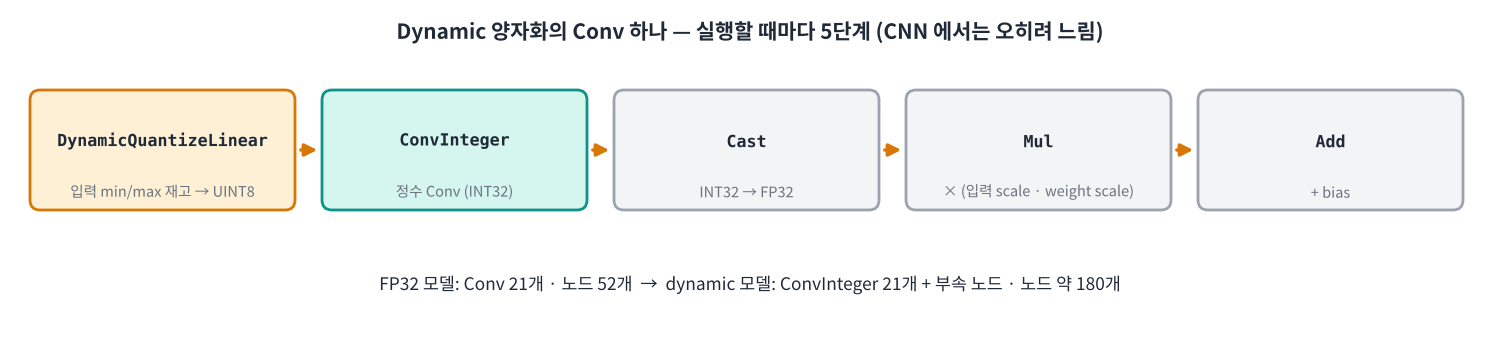

In [ ]:
#@title 🖼 그림 — dynamic 모델의 Conv 하나는 실행할 때마다 5단계를 거친다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day2/img/f2_dyn.png", embed=True, width=860))

**▶ 예제 2-A (제공 코드 — 실행만)** 왜 느려졌을까요? 두 모델의 **노드 종류별 개수**를 세는 `op_count(path)` 로 비교합니다 (`collections.Counter`). 실행 전에 예측해 보세요 — dynamic 모델의 노드는 늘었을까요, 줄었을까요?

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 2-A — 제공 코드 (그대로 실행)
def op_count(path):
    return Counter(n.op_type for n in onnx.load(path).graph.node)

c_fp32, c_dyn = op_count("rn20.onnx"), op_count("rn20_dyn.onnx")
print("FP32   :", sum(c_fp32.values()), "개", dict(c_fp32))
print("dynamic:", sum(c_dyn.values()), "개", dict(c_dyn.most_common(6)))

In [ ]:
assert c_fp32["Conv"] == 21 and c_dyn["ConvInteger"] == 21 and c_dyn["DynamicQuantizeLinear"] > 0
print("✅ Conv 21개 → ConvInteger 21개 + DynamicQuantizeLinear · Cast · Mul 이 잔뜩")

> 💡 **예제 2-A 해설** — dynamic 모델은 Conv 마다 '입력 min/max 재기 → 양자화(DynamicQuantizeLinear) → 정수 Conv(ConvInteger) → Cast → scale 곱(Mul)' 을 실행합니다. 노드가 52개 → 181개로 늘어 CNN 에서는 오히려 느려집니다. CNN 은 static 양자화를 써야 하는 이유입니다 (4교시).

### 🔁 바꿔보기 — 배치를 키우면?

`BS` 를 바꿔 보세요. 배치가 커지면 노드 실행 준비 비용이 여러 장에 나눠져 dynamic 의 손해가 줄어드나요?

In [ ]:
BS = 32                                       # 1, 8, 32, 128 로 바꿔 보세요
xb = X_ev[:BS]
a, b = bench(make_session("rn20.onnx"), xb, n=20, warm=3), bench(make_session("rn20_dyn.onnx"), xb, n=20, warm=3)
print(f"배치 {BS}: FP32 {a['fps']:.0f} 장/초 | dynamic {b['fps']:.0f} 장/초 | dynamic / FP32 = {b['fps'] / a['fps']:.2f}")

#### ⚠️ 자주 하는 실수

- "INT8 이면 무조건 빠르다" → dynamic 은 CNN 에서 오히려 느립니다. **측정이 먼저.**
- 시간을 한 번만 재기 → 첫 실행은 메모리 할당 · 최적화가 섞여 수십 배 느릴 수 있습니다. warm-up 후 여러 번.

#### 📌 2교시 정리

- `quantize_dynamic` = weight INT8 + 활성값은 실행 중 양자화. 보정 데이터 불필요.
- CNN 에서는 노드가 3배 이상 늘어 느려진다 (이 컴퓨터에서 약 9배). LSTM · Transformer 의 Linear 에 알맞다.
- `bench()` · `make_session()` · `op_count()` 는 오늘 계속 쓴다.

## 3교시 — 양자화 전처리: BatchNorm folding · quant_pre_process

양자화 전에 그래프를 정리해 두면 정확도와 속도가 모두 좋아집니다. 가장 중요한 정리가 **BatchNorm folding** — BN 의 곱셈 · 덧셈을 바로 앞 Conv 의 weight · bias 에 미리 합쳐 두는 것입니다.

$$\text{BN}(Wx) = \gamma \frac{Wx - \mu}{\sqrt{\sigma^2 + \epsilon}} + \beta = \underbrace{\left(\frac{\gamma}{\sqrt{\sigma^2+\epsilon}} W\right)}_{W'} x + \underbrace{\left(\beta - \frac{\gamma \mu}{\sqrt{\sigma^2+\epsilon}}\right)}_{b'}$$

> 🎬 **애니메이션** [D2-3 BN folding 과 전처리](https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/animation.html#d2-3)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

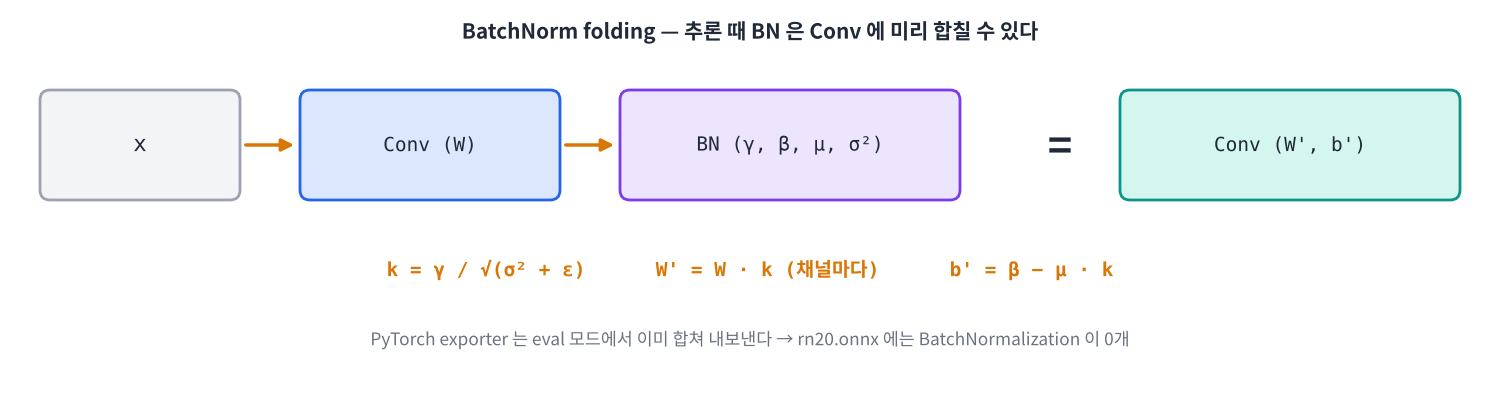

In [ ]:
#@title 🖼 그림 — Conv → BN 두 단계를 Conv 하나로 — 양자화할 텐서가 줄고 오차도 준다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day2/img/f3_bnfold.png", embed=True, width=860))

**✍️ 직접 구현 3-1** `fold_bn(conv, bn)` 를 만들어 folding 한 `(W', b')` 를 NumPy 로 돌려주세요. stem 의 Conv · BN 으로 확인합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 3-1 — 실행할 때마다 하나씩
show_hint("3-1", "7LGE64SQ66eI64ukIOqzse2VoCDqsJIgayA9IM6zIC8g4oiaKM+DwrIgKyDOtSkg4oCUIGBibi53ZWlnaHRgLCBgYm4ucnVubmluZ192YXJgLCBgYm4uZXBzYC4eVycgPSBXIMOXIGsg66W8IOyxhOuEkCDstpXsl5Ag66ee7LawIOKAlCBga1s6LCBOb25lLCBOb25lLCBOb25lXWAuHmInID0gzrIg4oiSIM68IMOXIGsgKGBibi5iaWFzYCwgYGJuLnJ1bm5pbmdfbWVhbmApLiBjb252IOyXkCBiaWFzIOqwgCDsnojsnLzrqbQgYiDDlyBrIOulvCDrjZTtlanri4jri6QgKOydtCDrqqjrjbjsnYAg7JeG7J2MKS4edG9yY2gg7YWQ7ISc64qUIGAuZGV0YWNoKCkubnVtcHkoKWAg66GcIOuwlOq+uOqzoCwg6rKw6rO864qUIGZsb2F0MzIg66GcLg==")

In [ ]:
# ✍️ 직접 구현 3-1 — BatchNorm folding
def fold_bn(conv, bn):
    # TODO: (W', b') 를 numpy float32 로 돌려주기
    pass

Wf, bf = fold_bn(model.stem[0], model.stem[1])
xt = torch.from_numpy(X_ev[:4])
with torch.no_grad():
    ref = model.stem[1](model.stem[0](xt)).numpy()
fold_diff = float(np.abs(F.conv2d(xt, torch.from_numpy(Wf), torch.from_numpy(bf), padding=1).numpy() - ref).max())
print("W'", Wf.shape, "| b'", bf.shape, f"| Conv+BN 과 최대 차이 {fold_diff:.2e}")

In [ ]:
assert Wf.shape == (16, 3, 3, 3) and bf.shape == (16,) and fold_diff < 1e-5; print("✅ Conv + BN = Conv(W', b')")

In [ ]:
#@title 🔒 정답 보기 3-1 — 강사가 알려 준 실습 3-1 잠금 코드를 입력하세요
show_answer("3-1", (
    "WKFHH3ECs+rhiXc00yYYGR/ZMs2CFfrj+FgX1/2FqAV6Ig0/ff52+ECnPCpZIZ6yAtj2nk8mDqnEB2KhK1PECI6Z"
    "1V2i+/kdy0lND0Qp6bxOn3gYKUrxmAfBPa8DNVZLD2evS/Nd6h+kwQVwngQ7QzDcfERzT+VYiSdPZ2H+InbacSlz"
    "peMYHF3Ff2ozCccE+qPeWzxbYY5KQbP+4Z4j7NiKxvBSpgowXA79xUfYeM5azYUz2fI3CmlO+gPNtdiU2zsFjabe"
    "/bA69HfT57ZIYWUDUWnMV5n3r1RMjVbypIruEAUAchpZMLW+SLMz0FRGBjlk/xT1P4j8nyuOnQdHHqjccd0NvspZ"
    "7wBNeaSxaifuWd9X8XemEo72Cphpt0U4mN7Aks/wG1mBu1B9sDrvRUXJXIohLAydCUeYXEJZHXWYTj+4Ezh+7nkT"
    "S7ds+bj6fNbp6oo6Ntude4I66VxRLcfR55AqU1hDcizIwqbvphqrj+jY2O6qwmk6UoKe/QDUUoSlPwbuFdmJHSmy"
    "uZB7R4ZII0bB0RggtZigWe5jBLddKmcwKaffNmEwTJhzfpZCuX0pSpTFxht1lVJJEGD/OmLIVJCXlgIHgmSaXb7A"
    "nkiWNHje49UTYbWoWOUxla3bEYAJoLTeq8gqiR7IWGG4md0Yzw9yyrXbshRet5ruZ9VKpQ4t4KkITLmRDxxKxHvb"
    "i20nxvZtrFTiH/bzpULDnfWUCCWnDBCYzzSyULeh/v4g/ILNOEF8+brRTyxqst6NUL5vgUhhpF5HrCX1vHPYb3V+"
    "5sHN80Ac80QH//VoRlZ+JY8fQftug5WaOw851FxnA9eC1cNG9QIGMXN38GQHhmgD59u0G/MwuItVKuhAPMqPMTG/"
    "iCn/VW4o9h9G1xrMfxyZ/OWS/l9gIX2rs1F8ElWYk10DRUcyuoF4c1bTSYZs7XvrfgLUzpI5PdLcFCiJIWw3DlAr"
    "o6n6kXr5njktWc/xwJRcGUO9xwXdon20FnUVr72tbiz54NqH3FCRrh5BGNGJlG5ldh2MMqnw7UxFXDdBrG/uqIbO"
    "LFlEDtNcQQtoLCqHUwyX3lV+th3p1WS6J/+h7P2fRM2/Ym0AFrsRsgAfg7u51Nlm1k+4z1qyBBJbxzGVSFyw0SJS"
    "vLby8CN2bQQ6VUagm3MXiC8epat4yGE/DqMpKp8qqWuJcBNnm7dbuHIS21IJ1FaceoWnb4nflDjeE3g7frb5F0BD"
    "rM7hR05ND5YabTHpE5hMbNsxRED56rQROjBXujbucBn/cwqlOyFDwgVqJy2tSdiNAeonpSC1IWTUQ/TKf85zpGoq"
    "aR2VZUtdtbnGKy/fXVEHK3lp/39aNWe+saGE/hRllNz3/U4Mryp+pJ9E4rmdp7GZiW6nPx39p5StUcyEfTOxyA=="
))


### 이미 folding 되어 있다?

PyTorch 의 ONNX exporter 는 **eval 모드**에서 BN 을 Conv 에 자동으로 합쳐 내보냅니다. 확인해 봅시다.

In [ ]:
g = onnx.load("rn20.onnx").graph
inits = {i.name: numpy_helper.to_array(i) for i in g.initializer}
first_conv = [n for n in g.node if n.op_type == "Conv"][0]
print("PyTorch BN 모듈:", sum(isinstance(m_, nn.BatchNorm2d) for m_ in model.modules()), "개 | ONNX BatchNormalization 노드:", op_count("rn20.onnx")["BatchNormalization"], "개")
print("ONNX 첫 Conv weight 와 직접 folding 한 W' 의 최대 차이:", float(np.abs(inits[first_conv.input[1]] - Wf).max()))

**✍️ 직접 구현 3-2** `quant_pre_process` 로 `rn20.onnx` → `rn20_pre.onnx` 를 만들고, 그래프의 **중간 텐서 모양 정보**(`graph.value_info`) 개수 `vi_before` · `vi_after` 를 비교하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 3-2 — 실행할 때마다 하나씩
show_hint("3-2", "YHF1YW50X3ByZV9wcm9jZXNzKOyeheugpeqyveuhnCwg7Lac66Cl6rK966GcKWAg7ZWcIOykhOyeheuLiOuLpC4e7KSR6rCEIO2FkOyEnCDrqqjslpEg7KCV67O064qUIGBvbm54LmxvYWQocGF0aCkuZ3JhcGgudmFsdWVfaW5mb2Ag4oCUIOq3uCDquLjsnbTrpbwg7IWJ64uI64ukLg==")

In [ ]:
# ✍️ 직접 구현 3-2 — rn20_pre.onnx 만들기, vi_before · vi_after
# TODO: quant_pre_process
vi_before = None   # TODO
vi_after = None    # TODO

print(f"value_info {vi_before} → {vi_after} | 노드 {sum(op_count('rn20.onnx').values())} → {sum(op_count('rn20_pre.onnx').values())}")

In [ ]:
assert os.path.exists("rn20_pre.onnx") and vi_after > vi_before and vi_after > 40 and abs(ort_acc("rn20_pre.onnx") - fp32_acc) <= 0.001
print("✅ 모양 정보가 채워졌고 정확도는 그대로")

In [ ]:
#@title 🔒 정답 보기 3-2 — 강사가 알려 준 실습 3-2 잠금 코드를 입력하세요
show_answer("3-2", (
    "b9YCq8AOuxODBvZD27Qx0wOdgWpGv+ca+0L3Nav7l+1ccqoXarutIpcRnpbZo1Y8gR8o25mfY1az82eiaNWUx9Pd"
    "eOsxrQVW4ancd5OlUy5kC3OlI3WljkcGCvAtW+kdo6nsl3yirCRm+KO+ftGXmiYySAHWDq1s4YIxV1exshVp29xX"
    "oYbBd4KIli4qz9IfAYuUFdbsyOpXX7B/hCYcc9yP8bnEGTuvzLPX5auFMno/QH792bRF2WMFkwBQDC3nXBKLiFy4"
    "yOAMnyFNPg1OWdsy5wboS0sM/aLtqT9F/XY4oL/6m+F8CzGEoQr0cJJOz29rzGh4Pp+7baw6ut5y0aCcCsB2ojon"
    "Vs8dwzkWXepDWJovxbBehnkXstVoRgX3aDKddegBZBayGg29PyxnFRs/LJNE3+aZuOZLsUFZiiQc1UX568HX8wJr"
    "83v47cPv3wcgDR706jE8cfvCJCWi3nUZaqnb2s1/Jf1xYFmk5ttsQdwNvTrDVnQpSDPYmAjQcgekqBoWMiH9az1L"
    "7uMJGlQpod7mOl/7chW5p2hr/9L8xdwf6cz7YJfoh8FKqSNq8P6CSm901iRKNMjrSFSnLNZBSQHT5IVRSO4Q3uvF"
    "13Jrpkl4m897S/DxQCnZSZc72gn3cge1SkHM4kcx+HDY9Vm8g1Lkjv5T3x/3FA9Hpjg5V4JtjJ/9Hk0uy6aypKfX"
    "THkWFyBiUJpvRcaZZKeoS0oHLrOxUe6ahN6E2zSU5EcfGZvgnj78qHgrz7sdTsLEl3AotjohX780/bdWcZ2MF7r+"
    "oSlAX8oQpLBikX44oqcatIY2eLbcpctwZgUWhRvoJ1eG/tCCCME9WFI9V8pSn0K5edpAQwGxAcYMok2MEwv7GEof"
    "FItJN/U2WDwEsrK5LmdPhzWrftyoRSJ5swu97u6hY3/SPcSjvlcxssLpCOzAuywAFtTUSRKozmF+nIbHGkKZaq0m"
    "d2pN1tqBZ72Jnen2gSn7DCriu+D0bYZsNgOSisfOlzqg5EI+eegRzh8kxjQ5qcMl/gDAVH47OPhCKx3ao6qVUw=="
))


#### 📌 3교시 정리

- BN folding: W' = W·γ/√(σ²+ε), b' = β − μ·γ/√(σ²+ε). 양자화할 텐서가 줄고 정확도가 좋아진다.
- PyTorch exporter 는 eval 모드에서 BN 을 이미 합친다 → ONNX 에 BatchNormalization 0개.
- 양자화 전에는 항상 `quant_pre_process` → `*_pre.onnx` 를 입력으로.

## 4교시 — Static 양자화: CalibrationDataReader · scale 검산

static 양자화는 **보정 데이터**를 모델에 흘려 각 활성값 텐서의 범위를 재고, 그 범위로 scale · zero_point 를 미리 정해 파일에 저장합니다. 보정 데이터를 건네는 방법이 `CalibrationDataReader` 입니다.

> 🎬 **애니메이션** [D2-4 보정 데이터와 static 양자화](https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/animation.html#d2-4)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

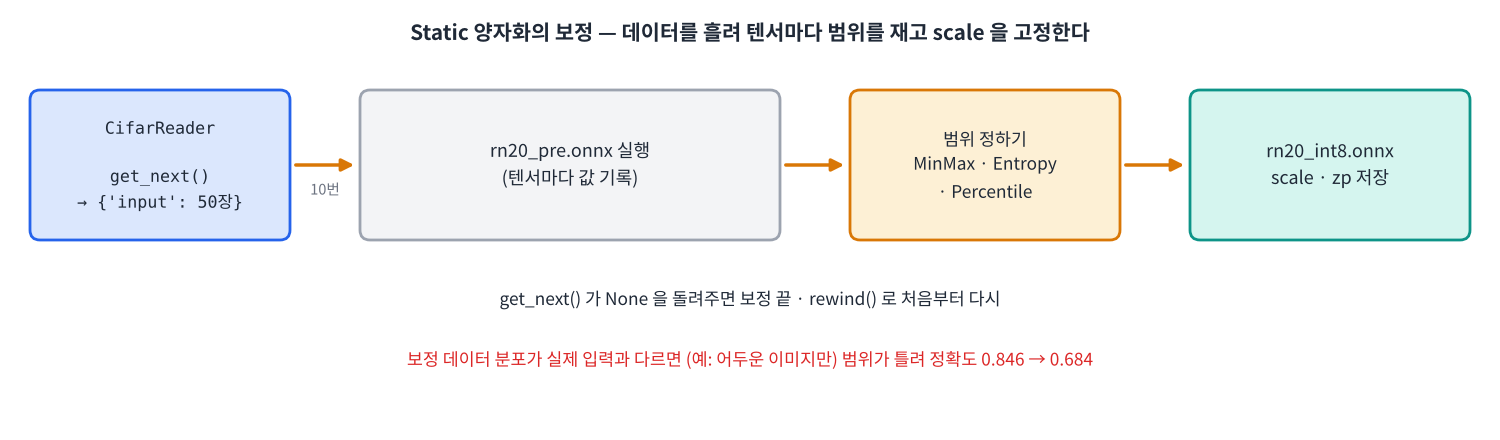

In [ ]:
#@title 🖼 그림 — CalibrationDataReader — get_next() 가 None 을 돌려줄 때까지 배치를 하나씩 건넨다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day2/img/f4_calib.png", embed=True, width=860))

**✍️ 직접 구현 4-1** `CifarReader(X, bs=50)` 클래스를 완성하세요. `get_next()` 는 `{"input": 배치}` 사전을 하나씩 돌려주고, 다 쓰면 `None`. `rewind()` 는 처음으로 되감습니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 4-1 — 실행할 때마다 하나씩
show_hint("4-1", "YF9faW5pdF9fYCDsl5DshJwgWCDCtyBicyDsmYAg7ZiE7J6sIOychOy5mCBgc2VsZi5pID0gMGAg7J2EIOyggOyepe2VqeuLiOuLpC4eYGdldF9uZXh0YDog7JyE7LmY6rCAIOuBneydhCDrhJjsnLzrqbQgYE5vbmVgLCDslYTri4jrqbQgYFhbaTppICsgYnNdYCDrpbwgYHsiaW5wdXQiOiDrsLDsuZh9YCDroZwg64+M66Ck7KO86rOgIOychOy5mOulvCBicyDrp4ztgbwg7Jiu6rmB64uI64ukLh5gcmV3aW5kYDog7JyE7LmY66W8IDAg7Jy866GcLg==")

In [ ]:
# ✍️ 직접 구현 4-1 — 보정 데이터 리더
class CifarReader(CalibrationDataReader):
    def __init__(self, X, bs=50):
        # TODO
        pass

    def get_next(self):
        # TODO
        pass

    def rewind(self):
        # TODO
        pass

r = CifarReader(X_cal)
n_batches = 0
while (b := r.get_next()) is not None:
    n_batches += 1
print("배치", n_batches, "개 | 배치 모양", r.X[:r.bs].shape)

In [ ]:
r.rewind(); first = r.get_next()
assert n_batches == 10 and set(first) == {"input"} and first["input"].shape == (50, 3, 32, 32)
assert CifarReader(X_cal[:120], bs=50).get_next()["input"].shape[0] == 50; print("✅ 50장 × 10 배치")

In [ ]:
#@title 🔒 정답 보기 4-1 — 강사가 알려 준 실습 4-1 잠금 코드를 입력하세요
show_answer("4-1", (
    "GAlUKRQ7C8L6ShTZ7n2kGLQPhiHxnipuv58bfq5vP2l/sMVRZio6jAGGtCl9CvHGIosfLP4IMDXl6RIdzdAyhLWS"
    "wrjimZxfH2yitBujAbXbOTbg/zUz3m4VIn2EBJ8XJUSO/W5i3jnNaHMoLtngBIrAMbpNVxSQQlUZdTKUjLENV4ga"
    "chiC8l/7C74guxfANN5OHZeU69c33A2ETvHfj67JZfUrfu8vHznOOtBaoOW8NIKu6m2h+v/BiYMOvXul4QCsOVGM"
    "9Fhf+yfz5iire7xRj+9PZIHArIKjcdTw2Q9TU9C6zsAXhSP4M8z/RQrojB8RJYhFv3qNt546ZDkFmOrBDjhcYhzo"
    "w3MNyRvEDv/JiJpf31TR+eKSpzXE6DlMwGhZxVunk87vrk738BWz4l/R6SaDBNqpZTXQhGVbf8f15hcAAVKlhfr8"
    "X6Q/i6qxaXVtsHZpX6LE4Iyni6WbYeJHw7F36pDmJc2ooBa4vTu0x5T06JajzVY3D0dyyJyVgRbYsKMsVrFNNemd"
    "XUKQvitEhppKF1wp48iqpeSxZqI/qersMUzU/yjqnCDTrjvTq9fuq+uazM2x6Ox3Lozo7HK6OsL2+a9Oh5hYzVlP"
    "Y0uOzvAYRNRSy82VqKG2DY3rv9Zr/6JjR5iFWlQ0HfU+R3yic2tb9W1BBfV5azEqnOGyB1LVnQA8XfRlKj/CHbJh"
    "TV3K8/1zmU7qVu3VKF1nKpmGDu/6omyHVhDet/acID74RTheiGsGr9lKC/PC348eO6mGbKM94pcGSHitwxgoeXbJ"
    "df9tjX5bW5sfuiLTZNkxRLmGp8JQb6oRuv1tW6PJ6eRVxJWeDeheNeh3wdDQSpQWB372iaP/+FcvSfogmR0yUsye"
    "VwBsxZyh4m1WMy+0EQLXanGbA0QHcLcIAWoyPy4JCYXmwdL/1+ZlvSZvsp9lYjDZK/ieiph/tCEJkyOGkJ6ZXZTZ"
    "klZaDBGzmYovyLg5TigNitsSu5idByJgU3VN2D24BCEAgxWkMD8TaIkYLBWX2eCdC1OEizdPeR2FA+uEXCSYXDwk"
    "YlNsksrcEP06pvOF5ZDlCQ=="
))


**✍️ 직접 구현 4-2** `rn20_pre.onnx` 를 static 양자화해 `rn20_int8.onnx` 를 만드세요. **QDQ 형식 · 활성값 U8 · weight S8 · per-channel**. 정확도 `acc_int8` 와 크기 `kb_int8` 을 구합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 4-2 — 실행할 때마다 하나씩
show_hint("4-2", "YHF1YW50aXplX3N0YXRpYyjsnoXroKUsIOy2nOugpSwgcmVhZGVyLCBxdWFudF9mb3JtYXQ9Li4uLCBhY3RpdmF0aW9uX3R5cGU9Li4uLCB3ZWlnaHRfdHlwZT0uLi4sIHBlcl9jaGFubmVsPS4uLilgHuyeheugpeydgCAz6rWQ7Iuc7J2YIGBybjIwX3ByZS5vbm54YCwgcmVhZGVyIOuKlCBgQ2lmYXJSZWFkZXIoWF9jYWwpYCAo7IOI66GcIOunjOuTpOyWtCDrhJjquLDquLApLh5RRFEgPSBgUXVhbnRGb3JtYXQuUURRYCwgVTggPSBgUXVhbnRUeXBlLlFVSW50OGAsIFM4ID0gYFF1YW50VHlwZS5RSW50OGAu")

In [ ]:
# ✍️ 직접 구현 4-2 — static INT8 (QDQ · U8/S8 · per-channel) → rn20_int8.onnx
# TODO: quantize_static
acc_int8, kb_int8 = None, None   # TODO

print(f"정확도 {fp32_acc:.4f} → {acc_int8:.4f} ({(acc_int8 - fp32_acc) * 100:+.2f}%p) | 크기 {kb_fp32:.0f} → {kb_int8:.0f} KB")

In [ ]:
assert abs(acc_int8 - fp32_acc) < 0.01 and kb_int8 < kb_fp32 / 2.5 and op_count("rn20_int8.onnx")["QuantizeLinear"] > 20
print("✅ static INT8 — 정확도 손실 1%p 이내")

In [ ]:
#@title 🔒 정답 보기 4-2 — 강사가 알려 준 실습 4-2 잠금 코드를 입력하세요
show_answer("4-2", (
    "hd/S/w4+S7TPyQdw+V/Ab+FB6c3MFHTXxW77A8icmbOk4vPl8NqxsGnmcSV1RSB1HgT+Hgb4vk2xALPXjNVB7CpC"
    "QzJI5UFByLdxqz/DKrbM2sUqNBls2ybDne2lZ/DcLNrpNtO9pmWjxF1sScBIe8RZUdRmQ0scUSWrEHypzikxujFZ"
    "/Y4bc9Tkx8TMvoB8EyEQj0bhoBqnMGNjrmnYogAWibMuH99vIdCtzG3cOv7hBLPtInGBlKPSkkKSsPMyPTwxPXFl"
    "sb6cwkH2qykhwUJSGoI6GnPDOyE+b3E9IeQWm0uAoE5rL3IE+qxBnIcRzLZzmSulIAJLvv2a5e8cR7QATEJ3hVMf"
    "/6Qj0JPBfeLUO14wot4y/28WA6juNLTwmbYmHgHjvBUjNg2zMIYRbk01Ma5iL0miVNZcBPnTlhlEu7jyhDBQV0cO"
    "Yms7xyyTagbBs7+Nnp2XlneiMBr8sbTeMHq3rNneFP3ZN2TGscMhpxojgW3XQsq5r4KnelZNpnVFqV7cNP4kQgDn"
    "6iPIVuKZcrxdihJvSy4MgQCtrzdLFNFgcLBj8mvg/B9D9Mk2xL4bsZe/rJeJOp5YfOyqqzTQKOr3/wi0WHJsdEmQ"
    "qNJsxSaW58bA7wQLaH5GjqlFk+tVqW2jowlPhDS9HD7Px6lwuTRlwL3qvhBC8IuIE7WkZb70UDjEzIGnOtBnoRUD"
    "jfpPKsczbZF7lQd2Q5cJl3C6tZqAcTttl2cyYVd0OG3NGN9ek6UytlnY5jrhaTQqP2oh+jhF3Ave1E8ku3DO2GY+"
    "iPgyqWD9DkWo7jrbjjwsjk967eE7ECksQcIVeFjwDwBDGjwa2vAg7B3eRfL8XDihGnqUGzp/M1M82lwFpJv7b0Z2"
    "awIN+SvfZtvkVL9upZqOItqX19LEGfDOCREf1vfg13vaHuWeo2JqYElg3HV6u0fVGVRgPqDu6YAJ1PYO66DUslyz"
    "cYMDJWo6zr6d33MZfC66Rj1OPXJwRyB1T4X2lmnCqk+wQGddgAxrblp/K5AsPC8Tny07dXTcxq0NRkOHo3y2KKUd"
))


### Day 1 함수로 검산하기

ONNX 파일 안의 **QuantizeLinear** 노드는 `(입력, scale, zero_point)` 세 개를 받습니다. 모델 입력 `input` 을 양자화하는 노드의 scale · zp 는 보정 데이터 500장의 min · max 로 정해졌을 것입니다 (MinMax 보정).

**▶ 예제 4-A (제공 코드 — 실행만)** `rn20_int8.onnx` 에서 `input` 을 양자화하는 QuantizeLinear 의 scale · zero_point 를 꺼내 (`ort_scale`, `ort_zp`), Day 1 `my_quant.calc_scale_zp` 로 보정 데이터의 min · max 에서 계산한 값 (`my_scale`, `my_zp`) 과 비교합니다. 실행 전에 예측해 보세요 — 두 값은 같을까요?

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 4-A — 제공 코드 (그대로 실행)
g8 = onnx.load("rn20_int8.onnx").graph
init8 = {i.name: numpy_helper.to_array(i) for i in g8.initializer}
qn = [n for n in g8.node if n.op_type == "QuantizeLinear" and n.input[0] == "input"][0]
ort_scale, ort_zp = float(init8[qn.input[1]]), int(init8[qn.input[2]])
my_scale, my_zp = my_quant.calc_scale_zp(X_cal.min(), X_cal.max(), 0, 255)
print(f"보정 데이터 범위 [{X_cal.min():.4f}, {X_cal.max():.4f}]")
print(f"ONNX Runtime : scale {ort_scale:.6f}  zp {ort_zp}")
print(f"my_quant     : scale {my_scale:.6f}  zp {my_zp}")

In [ ]:
assert abs(ort_scale - my_scale) < 1e-6 and ort_zp == my_zp; print("✅ Day 1 에 손으로 만든 함수와 ONNX Runtime 이 같은 답")

> 💡 **예제 4-A 해설** — QuantizeLinear 의 input[1] 이 scale, input[2] 가 zero_point 이름이고 실제 값은 initializer 에 있습니다. 범위 [−1.989, 2.126] → scale 0.016141, zp 123. ONNX Runtime 도 결국 Day 1 의 식 그대로 계산합니다.

**▶ 예제 4-B (제공 코드 — 실행만)** 보정 데이터가 **실제 입력과 다르면**? 보정용 이미지를 일부러 어둡게 (밝기 × 0.2) 만들어 보정한 `rn20_dark.onnx` 의 정확도 `acc_dark` 를 구합니다. 평가는 원래 밝기의 평가용 이미지로 합니다. 4-2 와 달라진 것은 **reader 에 넣는 데이터 한 곳뿐**입니다.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 4-B — 제공 코드 (그대로 실행)
X_dark = preprocess((cal["images"] * 0.2).astype(np.uint8))
with quiet():
    quantize_static("rn20_pre.onnx", "rn20_dark.onnx", CifarReader(X_dark),
                    quant_format=QuantFormat.QDQ, activation_type=QuantType.QUInt8,
                    weight_type=QuantType.QInt8, per_channel=True)
acc_dark = ort_acc("rn20_dark.onnx")
print(f"정상 보정 {acc_int8:.4f} | 어두운 이미지로 보정 {acc_dark:.4f} ({(acc_dark - fp32_acc) * 100:+.1f}%p)")

In [ ]:
assert acc_dark < acc_int8 - 0.05; print("✅ 보정 데이터의 분포가 틀리면 정확도가 크게 떨어진다")

> 💡 **예제 4-B 해설** — 어두운 이미지는 정규화 후 값이 대부분 음수 쪽에 몰려, 보정이 잡은 범위가 실제 입력보다 좁아집니다. 실제 입력의 밝은 값은 모두 잘려(clipping) 정확도가 0.845 → 0.684 로 떨어집니다. 보정 데이터는 '많이' 보다 '실제 현장 입력과 비슷하게' 가 중요합니다 — Day 1 6교시 clipping 오차를 모델 전체에서 본 것입니다.

### 🔁 바꿔보기 — 보정 장수

`N_CAL` 을 바꿔 보세요. 10장으로도 괜찮을까요? (실측: 10장 0.8445 · 50장 0.843 · 100장 0.845 · 500장 0.845)

In [ ]:
N_CAL = 10                                    # 10, 50, 100, 500 으로 바꿔 보세요
with quiet():
    quantize_static("rn20_pre.onnx", "rn20_ncal.onnx", CifarReader(X_cal[:N_CAL], bs=min(50, N_CAL)),
                    quant_format=QuantFormat.QDQ, activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8, per_channel=True)
print(f"보정 {N_CAL}장 → 정확도 {ort_acc('rn20_ncal.onnx'):.4f}")

#### ⚠️ 자주 하는 실수

- 보정 데이터에 **학습 때와 다른 전처리** (정규화 빠짐, RGB/BGR 뒤바뀜) → 범위가 엉뚱하게 잡힙니다. 평가 · 배포와 **같은 preprocess()** 를 쓰세요.
- `get_next()` 가 None 을 돌려주지 않음 → 보정이 끝나지 않습니다.
- 사전 키를 ONNX 입력 이름과 다르게 씀 → 오류.

#### 📌 4교시 정리

- static 양자화 = 보정 데이터로 활성값 범위를 미리 재서 scale 고정. CNN 의 표준.
- `CalibrationDataReader` 는 `get_next()` (끝나면 None) · `rewind()` 두 함수.
- 파일 안의 scale · zp 는 Day 1 식 그대로 — 검산 가능.
- 보정 데이터는 **현장 입력과 같은 분포**로. 장수는 수백 장이면 충분.

## 5교시 — QDQ vs QOperator: 그래프 모양 · U8 / S8

같은 static 양자화라도 ONNX 그래프에 담는 방식이 두 가지입니다.

| | QDQ (QuantizeLinear · DequantizeLinear) | QOperator |
|---|---|---|
| 모양 | 원래 Conv 앞뒤에 Q · DQ 노드를 끼움 | Conv 자체를 **QLinearConv** 같은 정수 연산자로 바꿈 |
| 장점 | 원래 그래프가 보여 읽기 쉬움 · **TensorRT 등 다른 런타임의 표준 입력** | 노드 수가 적고 ORT CPU 에서 바로 빠름 |
| 실행 | 런타임이 Q-Conv-DQ 를 묶어(fuse) 정수 연산으로 바꿔 실행 | 그대로 실행 |

> 🎬 **애니메이션** [D2-5 QDQ 와 QOperator](https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/animation.html#d2-5)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

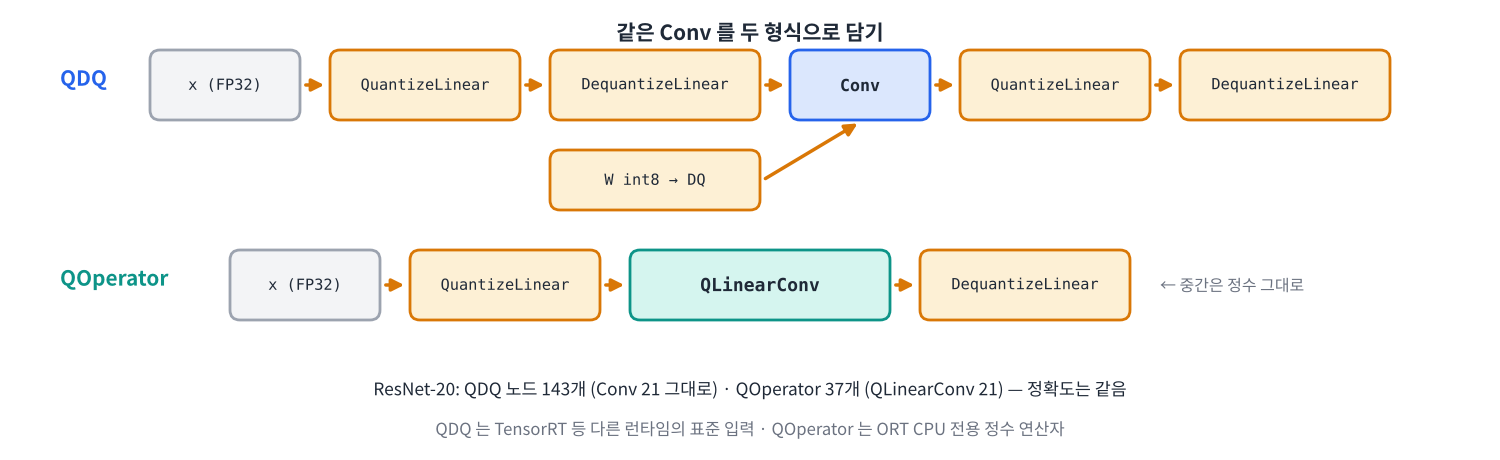

In [ ]:
#@title 🖼 그림 — 같은 Conv 를 두 방식으로 — QDQ 는 Q · DQ 를 끼우고, QOperator 는 QLinearConv 하나로
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day2/img/f5_qdq.png", embed=True, width=860))

**✍️ 직접 구현 5-1** 같은 설정(U8 / S8 · per-channel)으로 **QOperator** 형식 `rn20_qop.onnx` 를 만들고, `op_count` 로 두 형식의 노드 구성을 비교하세요. 정확도 `acc_qop` 도 구합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 5-1 — 실행할 때마다 하나씩
show_hint("5-1", "NC0yIOyZgCDqsJnsnYAg7Zi47Lac7JeQ7IScIGBxdWFudF9mb3JtYXQ9UXVhbnRGb3JtYXQuUU9wZXJhdG9yYCDrp4wg67CU6r+J64uI64ukLh5vcF9jb3VudCDripQg7JiI7KCcIDItQSDsl5DshJwg7KCc6rO165CcIO2VqOyImC4=")

In [ ]:
# ✍️ 직접 구현 5-1 — QOperator 형식 rn20_qop.onnx 와 노드 비교
# TODO: quantize_static (QOperator)
c_qdq, c_qop = None, None   # TODO
acc_qop = None              # TODO

print("QDQ      :", sum(c_qdq.values()), "개", dict(c_qdq.most_common(5)))
print("QOperator:", sum(c_qop.values()), "개", dict(c_qop.most_common(5)), f"| 정확도 {acc_qop:.4f}")

In [ ]:
assert c_qop["QLinearConv"] == 21 and c_qdq["Conv"] == 21 and c_qdq["DequantizeLinear"] > 50 and abs(acc_qop - acc_int8) < 0.005
print(f"✅ QDQ {sum(c_qdq.values())}개 vs QOperator {sum(c_qop.values())}개 — 정확도는 같다")

In [ ]:
#@title 🔒 정답 보기 5-1 — 강사가 알려 준 실습 5-1 잠금 코드를 입력하세요
show_answer("5-1", (
    "49ZNqznV+pO6o9JGyGxAjseGVPOEUhaXwr7qTaXtCJblTyZLblBfamcppA5ZTxDnYygDerEs3Fpaa4zFeepDSCxd"
    "ivxlFnzgUBjW6J3tOX7oPLeFksg7EiyyNOl8pd1iootk44COXZ5rF+WU0YXuy4vhXmByA8XHGESv4naNjd9w5pPb"
    "PI7jDqRN+SsH6smeXGLhjzFcZ8yRZm7neLaEMxIXq0zJVk01drZa5dsSPtQMDtT802aKr5/wFguHxmlS+q7eBkG7"
    "+/By/uJfE8cSCB0oeQN/44QiXBNlZXs5bl6Y3cLR2aOBb6D6GpXlU6xFOkJQ5zMi0Q1OFb/qLjEzugnLHepZTROd"
    "JwvgTwVhQal6CCuGGZwLKMFPwdFpSVglkeJzD+ctBQSwA7cByZoNurLOi2mb9+VAbZTWefEyIlV5W/ecuYKgAHnP"
    "zGYf2lKc1vBqoDCvfUVimkmDKzIZbDL5P1veZwqSmr4srhpR6YDTw8k2fri50d0MSyYiABhSXFn4b6bNqpW/oB0a"
    "eJPsaaz7AMruaSSovVkeEN2Lxa5rMM49AIHO7PONBjpwemQi3cPNSlDPe8wOi8FAU+U0LnmTpBEl3H34Tn9cO+Os"
    "bfQyw/NUdYyOJv1R+5JQxRn8DHaPGRW9rtOKT/e44J0ltWZ5D1aNqHpv9pK+W+7FR8GryCqYOVkiu7tQvYNu9lrn"
    "FlCjFDQB++4Lgo/IoRW1k0B66W2LAGEkY6TTMCmkF9OMidE9nS8m7m5Y3KtA3xE5cXeNxyJbwh59jhvoa7f3puqO"
    "S7ZSh9dsTsvxkQagkz0v52ZgK7rt2TBViY5s3Hb9H+LoII1a2cLTG5/MAwcE7jcKZZTcNlDaskYJit6rG9a7y1Tg"
    "kO7GDPNHgVuCD+eVdTTY3A+CSWTfwatbmqbeQk9GCivQ9OMjhI9SwrJMtGm2huloN3aqMPNOC/2debzd2Fmd47ix"
    "IQYIb7I8Rw34zdO3LNc4YG9lihebO+h5RxbOLtCwjFJR05ygXuh+3sUFBngeuhVfitHi3SxMEaNZR6Kd1XV6WZKZ"
    "Z37BKUmf1jWaXWuzGXBhF2T/scNwIdhQJd+mPU7CQhXOCT/kfgC1BcCK8mg="
))


### weight 는 어떻게 들어 있을까

QDQ 모델에서 weight 는 **INT8 initializer → DequantizeLinear → Conv** 로 연결됩니다. per-channel 이므로 scale 이 채널 수만큼 있습니다.

**▶ 예제 5-A (제공 코드 — 실행만)** `rn20_int8.onnx` 의 **첫 Conv** 로 들어가는 weight 의 DequantizeLinear 를 찾아 INT8 weight `wq`, scale `ws` 를 꺼내고, 역양자화한 값과 3교시에 직접 folding 한 `Wf` 의 최대 차이 `w_err` 를 구합니다.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 5-A — 제공 코드 (그대로 실행)
dq_out = {n.output[0]: n for n in g8.node if n.op_type == "DequantizeLinear"}
conv0 = [n for n in g8.node if n.op_type == "Conv"][0]
dqw = dq_out[conv0.input[1]]                                  # Conv 의 두 번째 입력 = weight
wq, ws = init8[dqw.input[0]], init8[dqw.input[1]]
w_hat = wq.astype(np.float32) * ws[:, None, None, None]       # 대칭 → zp = 0
w_err = float(np.abs(w_hat - Wf).max())
print("wq", wq.shape, wq.dtype, "| scale", ws.shape, f"| 최대 오차 {w_err:.5f} ≤ 채널 scale/2 최대 {ws.max() / 2:.5f}")

In [ ]:
assert wq.dtype == np.int8 and ws.shape == (16,) and w_err <= ws.max() / 2 + 1e-6; print("✅ per-channel 대칭 INT8 — Day 1 그대로")

> 💡 **예제 5-A 해설** — Conv 의 input[1] 은 weight 를 만드는 DequantizeLinear 의 출력입니다. 그 노드의 입력이 INT8 weight · scale(16,) · zp. weight 는 대칭(zp = 0)이라 역양자화는 q × scale — 오차는 채널 scale 의 절반 이하입니다 (Day 1 4 · 5교시).

### 활성값 U8 vs S8 — CPU 에서는 차이가 크다

x86 CPU 의 INT8 연산 명령은 **'부호 없는 8비트 × 부호 있는 8비트'** 조합(U8 · S8)에 최적화되어 있습니다. 활성값까지 S8 로 만들면 ONNX Runtime 이 빠른 경로를 못 쓸 수 있습니다.

**✍️ 직접 구현 5-2** 활성값을 **S8** 로 바꾼 QDQ 모델 `rn20_s8.onnx` 를 만들고, U8 모델(`rn20_int8.onnx`) · FP32 와 배치 1 지연 시간을 비교하세요 (`lat` 사전: 이름 → mean ms).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 5-2 — 실행할 때마다 하나씩
show_hint("5-2", "NC0yIOyZgCDqsJnsnYAg7Zi47Lac7JeQ7IScIGBhY3RpdmF0aW9uX3R5cGU9UXVhbnRUeXBlLlFJbnQ4YCDroZwg67CU6r68IOqyg+ydtCBTOC9TOCDrqqjrjbjsnoXri4jri6QuHmBiZW5jaChtYWtlX3Nlc3Npb24ocGF0aCksIHgxLCBuPTIwMCwgd2FybT0yMClbIm1lYW4iXWAg7J2EIOuqqOuNuOuniOuLpCDsnqzshJwg7IKs7KCE7Jy866GcLh7ruYTqtZDtlaAgNOqwnDogcm4yMF9wcmUub25ueCAoRlAzMiksIHJuMjBfaW50OC5vbm54LCBybjIwX3M4Lm9ubngsIHJuMjBfcW9wLm9ubngu")

In [ ]:
# ✍️ 직접 구현 5-2 — 활성값 S8 모델 rn20_s8.onnx 와 지연 시간 비교
# TODO: rn20_s8.onnx 만들기
lat = None    # TODO: {"FP32": ms, "QDQ U8/S8": ms, "QDQ S8/S8": ms, "QOperator U8/S8": ms}

for k, v in lat.items():
    print(f"{k:16s} {v:.3f} ms  ({lat['FP32'] / v:.2f}× FP32 속도)")

In [ ]:
zp_dtype = init8[qn.input[2]].dtype
assert zp_dtype == np.uint8 and len(lat) == 4 and all(v > 0 for v in lat.values()) and ort_acc("rn20_s8.onnx") > fp32_acc - 0.01
print("✅ 측정 완료 — 이 컴퓨터에서 S8/S8 이 U8/S8 보다", f"{lat['QDQ S8/S8'] / lat['QDQ U8/S8']:.1f} 배 느림")

In [ ]:
#@title 🔒 정답 보기 5-2 — 강사가 알려 준 실습 5-2 잠금 코드를 입력하세요
show_answer("5-2", (
    "4/NxVZb+4Ral5gTSgziMooOtHAY48JwlnDo0HTdQcltoU2rWHQjXhhDxtbuZOKBVEx66luRzCfwQpZ/OGTFJVUNL"
    "Btz3A2zmokaBq4klEQcQYyscq36nsi8eYlpu1V5hOi+iBz6e2SE+c9i6/EfYt746NaRYuhHEEtDxiHhiucLCOQ7D"
    "V2apasikjricjBmRzLeG3VzAsQPOjs7XVe0CrpAqnwwkfDGIalqMefaZHtlsSL0+rmhtAUZbfRcmxrHKPCmhJqs+"
    "NoJYIrT/rRCAh0mRCcwKPtkmwEqbz82X3BfoQDsZSLGcun+e+csMlke2BP7lbJoktbQzHV5lYUwH7GUOa8IntRvV"
    "xFyCmS7egW9hxH9eJj5qpfZZEiBmvxmD4HpRBgOrFEnJtgnxit5naijpcuyHl3KNR/Ib5aIjh0AVYdALxW3Z7Wh3"
    "wwUCm4cdKGMNR03AaMcm/jemL/23rSOA+dttuKhI8F84z/PVPwq3TrgA92UdhNi1xCnlEBzuIkXex+uMatmSG3/j"
    "yJUrQ8Gk5rirv4iKZuu0gi1+MmO1xgZotVzLhkPsuyqsmDkdnrgxQ4KbKbb2Niq23o9LRQAedz8TvJNOWjr35tbo"
    "vIZM5HvsNiVQo6qvuM3pv9aV1ihA8PWrhhuffsBPfLnmhfs9x2eDJav2Tq/bcHfUVEB5VIhmh7F0h9MPpY/EYI7m"
    "bwip4BhP6qnHcdntvCQ4o5M4l4VVc8xtnvtobrO+q7vpj5Y22r9lf6t3T/86mDNuwcPrkLjTl8GuDJMVRYrhjX1L"
    "lk+mni3JLUKAhfE0zgmI7orosxcp7EUDsTBI6Grk0UOyYku7eYnmwjXpyySSsWRs5FJp0EBe36jUlavEgfr7vWbK"
    "fsKjAFlPfPfjQ6GzbFFpVnKbcq7d0SvIX+035M9xkNxwOJvRxtVMK2oYuwPG1nuMpXEvR8ENvmJM3zJO4BMONkV/"
    "+PBxPxnU2c28XNdjj3xJ0Wce41Cmpj2dOTpu+Yd0abxjvRf+W3qB9+2i9XYxxnxCFuUqzTOihxQLzZxfDT22TYPC"
    "CfhY2Miod44GlmZE5zOZAa8GqNPdGIntVK4D7vhFjcTdIPbEECmowRpKtLZI1Go5YU68H/Fma2adM8M9bDgCy037"
    "HguSamp63zF6THBAWZaPbgUzlxhHrJiYQSv3gw5MabliI0bqhLns9zpna6gf+tC+071yswIjU/GVZgV4lM8ete0B"
    "T5WDXk8QoSvDDSL9rzG61bfDfIYvD5M4TA+PeXFHuUuL6LDm0yeNLMcHDxoSUdLj+REa5j+49AJVd6IgHfLYNbfG"
    "tzUuQVRIhkqRrw=="
))


#### 📌 5교시 정리

- QDQ = 원래 그래프 + Q/DQ (TensorRT 등의 표준 입력), QOperator = QLinearConv 같은 정수 연산자 (ORT CPU 용).
- weight 는 INT8 initializer + per-channel scale + zp 0 — Day 1 의 대칭 per-channel 그대로.
- x86 CPU 에서는 **활성값 U8 · weight S8** 이 빠르다. 형식 · 자료형은 **배포 장치에서 측정**해 고른다.

## 6교시 — Calibration 방법 비교: MinMax · Entropy · Percentile

Day 1 6교시에서 범위를 어디까지 잡을지(clipping) 직접 실험했습니다. ONNX Runtime 의 `calibrate_method` 가 그 선택입니다.

| 방법 | 범위 | Day 1 에서 |
|---|---|---|
| `CalibrationMethod.MinMax` | 본 값의 최솟값 ~ 최댓값 | 3 · 4교시 |
| `CalibrationMethod.Percentile` | 아주 드문 큰 값을 잘라냄 (기본 99.999%) | 6-1 · 6-3 |
| `CalibrationMethod.Entropy` | 원래 분포와 양자화 분포의 차이(KL)가 가장 작은 범위 | (오늘 처음) |

> 🎬 **애니메이션** [D2-6 보정 방법 비교](https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/animation.html#d2-6)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

**✍️ 직접 구현 6-1** 3가지 방법 × per-channel (False / True) = 6개 모델을 만들어 정확도 표 `calib_df` (열: `method`, `per_channel`, `acc`) 를 만드세요. 파일 이름은 `rn20_{방법}_{pc|pt}.onnx`.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 6-1 — 실행할 때마다 하나씩
show_hint("6-1", "7J207KSRIGZvcjog67Cp67KVIDPqsJwgKGBDYWxpYnJhdGlvbk1ldGhvZC5NaW5NYXhgIMK3IGBFbnRyb3B5YCDCtyBgUGVyY2VudGlsZWApIMOXIHBlcl9jaGFubmVsIFtGYWxzZSwgVHJ1ZV0uHu2MjOydvCDsnbTrpoQgYGYicm4yMF97bWV0aC5uYW1lfV97J3BjJyBpZiBwYyBlbHNlICdwdCd9Lm9ubngiYC4ecXVhbnRpemVfc3RhdGljIOyXkCBgY2FsaWJyYXRlX21ldGhvZD1tZXRoYCwgYHBlcl9jaGFubmVsPXBjYCDrpbwg64SY6riw6rOgLCDqsrDqs7zrpbwgYHsibWV0aG9kIiwgInBlcl9jaGFubmVsIiwgImFjYyJ9YCDsgqzsoITsnLzroZwg66qo7JWEIERhdGFGcmFtZS4=")

In [ ]:
# ✍️ 직접 구현 6-1 — 보정 방법 × per-channel 6개 모델 정확도 표
calib_df = None   # TODO: 열 method · per_channel · acc

display(calib_df)

In [ ]:
assert len(calib_df) == 6 and set(calib_df.method) == {"MinMax", "Entropy", "Percentile"} and (calib_df.acc > fp32_acc - 0.01).all()
print("✅ 6개 모두 손실 1%p 이내 — 가장 좋은 것과 나쁜 것의 차이", f"{(calib_df.acc.max() - calib_df.acc.min()) * 100:.2f}%p")

In [ ]:
#@title 🔒 정답 보기 6-1 — 강사가 알려 준 실습 6-1 잠금 코드를 입력하세요
show_answer("6-1", (
    "MaVVGBmFItuz2QlCT4Q8pWw1kxGdfrYbJRXtX1DdnkxFxWgA+MYPEGNODc3SUVFFy7Yqc8nSApmLkQJDP7XCSmzN"
    "I58FEk32f8x+tQHe4KHm3cB2/eFR1C4MOTBeoVwQZTfyJEgErLQ9CL2zV2fs98Y+iRHGo/xW9nLdjuikhO8Yzj6E"
    "SqpZdqHpI8m05rjRJlIsjjFLXuPXRwWlqA8CbaYcfVeimbLrXIaj9USzTMZzDWqVe6M+SF8UJjSzmwNMxAc5PFvY"
    "5clOPqc1cthGjMbbKxypXXLUtQGbfpT0y3TgCPjdAr6umYfujpvK/BARwNjXUCk4bz9JQkldR2J+1NfM7qOObCZC"
    "M17qxPs2ZMZwgkDXPxXQIZ2WLhhjsxHuMb1AwqrZvePmpcon2pkeCqjmaVbVhVB/nC0zlJ6UaiTmot9gGsnCSX/h"
    "8jnmbNzfu/JOoiMDaFQ2LHz4fWOVWf7jMMsgSG2p8nZ1OoEYDKiEzzZWyyCYQ395PAw7+rK7LQ3PzCz0cH01+mKd"
    "cUO+SsJ1tjmnuK/KIpL7mYG+eUCAUc8yMzMNnnlnVpjESRS7p7KACjUEY1/C1BCA9ZCdtsik68xutOjONgSN6UYD"
    "l5c1/dYA9ULbo2SNPoIiCeo6JNc9AipmQeWb+OClfr1T3CtE758VOF0tnQRSsAwPv1NJl1I7JN1ex7jdkeVlDOtt"
    "KZEvRMihqheWDCVI/nnGStOf0h6KGN+v4WW26ZW7IIAa2UPVgw7yXGKgccO9s7J8TaRDL9DyLKViHQi4rSZFZutU"
    "Wka6fLiZAptRW7wm1hJUrt5fYRSMlBatetwtImv7dVcGTsMul2oETdAqzsVpUHGaJdL119hOWhXpPxj5+vzxgsSi"
    "gg0hgYTWkD3V/n1kiHBl3C9dyHk1Zbl8cHX0zCNa8VF+FJyVhHhtcIySDKsu08zbInPFkRqyUcR1HVLA0ULiokno"
    "c8OkGzhgfMQb28bnXP9OXbX8VHNzEIpyxa+l2FGCzf7Xc5smz+q/nB/NoVpjlz1o0XOz42p34M5y7njGTLmM0dV5"
    "C5imnEy0FbgJp0MmSMcX5D+UniaAU0NQsOFdypz1dLzjqhCOJlVIg/TY78cHbOMcok/+AQ7w6ckva5YcGJeRK4ch"
    "X7GzuigQZH7zzOIhCYhZdr8vJjFabJo0aywFM1RK3Cu16e5jlS337tiSBzl+OS9RlvPM10gBAtElbd6+xSDM4DQZ"
    "wlXgmzxtXNQlN1pRrXAU79KWE+h2Q8e2Jno5ypvwom0X"
))


정확도는 비슷했지만, **고른 범위**는 정말 같을까요? 활성값마다 scale 을 비교해 봅니다.

**✍️ 직접 구현 6-2** `act_scales(path)` 로 모델의 QuantizeLinear 마다 `{입력 텐서 이름: scale}` 사전을 만들고, per-channel 모델 기준으로 **Percentile / MinMax**, **Entropy / MinMax** scale 비율의 평균 · 최솟값을 구하세요. 가장 많이 잘린 텐서 `most_clipped` 도 찾습니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 6-2 — 실행할 때마다 하나씩
show_hint("6-2", "YWN0X3NjYWxlczogUXVhbnRpemVMaW5lYXIg66eI64ukIGB7bi5pbnB1dFswXTogZmxvYXQoaW5pdGlhbGl6ZXJbbi5pbnB1dFsxXV0pfWAuHuyEuCDrqqjrjbgo4oCmX3BjLm9ubngp7J2YIOyCrOyghOydhCDrp4zrk6Tqs6AsIE1pbk1heCDsgqzsoITsnZgg7YKk66eI64ukIOu5hOycqOydhCDqs4TsgrDtlbQgbnVtcHkg67Cw7Je066GcLh7qsIDsnqUg66eO7J20IOyemOumsCDthZDshJwgPSBQZXJjZW50aWxlL01pbk1heCDruYTsnKjsnbQg6rCA7J6lIOyekeydgCDtgqQg4oCUIGBtaW4oc19tbSwga2V5PWxhbWJkYSBrOiAuLi4pYC4=")

In [ ]:
# ✍️ 직접 구현 6-2 — 보정 방법이 실제로 고른 scale 비교
def act_scales(path):
    # TODO: {양자화되는 텐서 이름: scale}
    pass

s_mm, s_en, s_pc = None, None, None   # TODO: MinMax · Entropy · Percentile (per-channel 모델)
r_pc = None          # TODO: Percentile / MinMax 비율 배열
r_en = None          # TODO: Entropy / MinMax 비율 배열
most_clipped = None  # TODO
print(f"활성값 {len(s_mm)}개 | Percentile/MinMax 평균 {r_pc.mean():.3f} 최소 {r_pc.min():.3f} | Entropy/MinMax 평균 {r_en.mean():.3f} 최소 {r_en.min():.3f}")
print("가장 많이 잘린 텐서:", most_clipped, f"(범위 {r_pc.min():.0%} 로 축소)")

In [ ]:
assert len(s_mm) > 30 and r_pc.mean() < 0.95 and r_pc.max() <= 1.0 + 1e-6 and most_clipped in s_mm
print("✅ Percentile 은 범위를 평균", f"{(1 - r_pc.mean()):.0%}", "줄였는데도 정확도는 그대로")

In [ ]:
#@title 🔒 정답 보기 6-2 — 강사가 알려 준 실습 6-2 잠금 코드를 입력하세요
show_answer("6-2", (
    "4ZQ0VVPN+B2Z32FOaquPUG48rc7cAkKsUkzn3DNRCyoqCktulpWwGAolJeNNznw5JNp5ivJyPAXehCA9fibXDjea"
    "QffFXpBpMQ6xbJb4gBUVMgeHPDncx3xGWgCm/3BAABDNgzlsePSwzeIvxupL1TuKhwLSEGOqeHJCbKMJdPusx725"
    "wT6t7z4IIm+i44Jc69jGnlHLbHAqWR/qqYiN6G7+nv6S2EGLwRa5r4MZv7SmUNWQ3CZ1OZ3e6Rq5r9eLKWeTEAfr"
    "0BJgMrCrvc0kOW0jTbOk7mCR1RSY/PgxID8U8TiWQezo7nBQWcXiQZVgMEifE32oMP6OIicztMLR3SoHBCxZQ7Ws"
    "I48vubrB09HNQLO07OeXnG51Wyd5dHNBeQim12hyAU6eO2jg2D/c895P8SurM8l48iSaaVDYo5FE1t4sft2vn23F"
    "0eQ7ZeEd1++A3R3ZFgKY4QzF5k4A8/aDi2vQO9BLFQo6cn9u78BlSUlFB5Xtr6bbQBTYtzKCddtMl8VOIceuYNz1"
    "pxGHFPj/CZESSIkgoHCo+WCY7DfN8V/I3nxEhL7zF0oMVro51E6bS2+q+/rGApARjBSZau4FQaKPHL7cNMP23SyT"
    "3DHYlul22VuY3P65LilSc5xuiqBD+3s8eB1I/ebNnpzWmQ09W/t8tYcUZf4xm7/7jHrPMcTejDE70rLC25t7WPLQ"
    "J9Tc3RGZrqXShOGx9V0ixCPO4xXE2969zXClv5OD1kxcW1Lm56O+sS76qqaqjn8NJhDYtfeU1O5acGRGfSkDEGJL"
    "iOuk76DSkeGmWEJW4TxDB2hPIeRuajRH/RDsShrVdLcrglIi4Yj7bDH+85SdDpFEeYwEP9WUzgeNdX4ZFZG02zG3"
    "UuM4UlViRQ2eNap4t/b8mz10kfsjlegM9YZgqctr0H6nWmdcUsjrou5tAfTY/MO3AEX8A/kxgliigWa0QwCNNYUV"
    "9aUCfpO7RYJ+SQWj+opsvrpTjPXq0KorCv78+y6cwGIDC59RAkkCQTVDYpg53qNYWVFVTk/0ePczfrfZ3RAB88Xu"
    "D8Dczq29st9/ik2JGcV/Z3yDyvfgjcoY2JMDMt9cdU25gLbQ8VQZODCCcJsBaTlJAa0Fz9d1ywXgxeO4DjxGyj2J"
    "VsMRTGZ45eJ4xI+KpI78+h/D5tymiVhCkjvx7GY97M2Y78lahVW1lqqrpPgOH73WSqAN6NwKPxq54KxV1LU4CK2B"
    "mkEolRoFpzqTi1ValT+g4hdRGoSM3Mp7cARAvdZLKau2oDPUeirt1lW+Pm+RGO7c/v+1eMnlV+mGjE9F+ljImWlj"
    "rvIeCWHaRs0ORU27nl/30cAtb/XoVAVxWhvH6EQ/ccXmwql/IePvFxs38dWJrPlNzcrL9SyI9Dm+osZ0UaLKElD5"
    "V2dOqNdZ0S/p/lcrEmMvoWGy6MSmn5+KVV6NeDeMJLq4Fx2DJz2HO6oBLppne6IKEstLY1zf/Us2XnxybdH7JFY/"
    "ISEwVvzUJI2hVbvc9OeyyNS1syUarQ0pj+0DwI47JlSiF5X0T+jGnZXNqN816dWEo9EMfPxdQPBcIx3kgTH1BA4F"
    "3xO/rfb5l9wZAoW1uilHlO9/OoVX0qh5I/gI/RYWyfcYJgc="
))


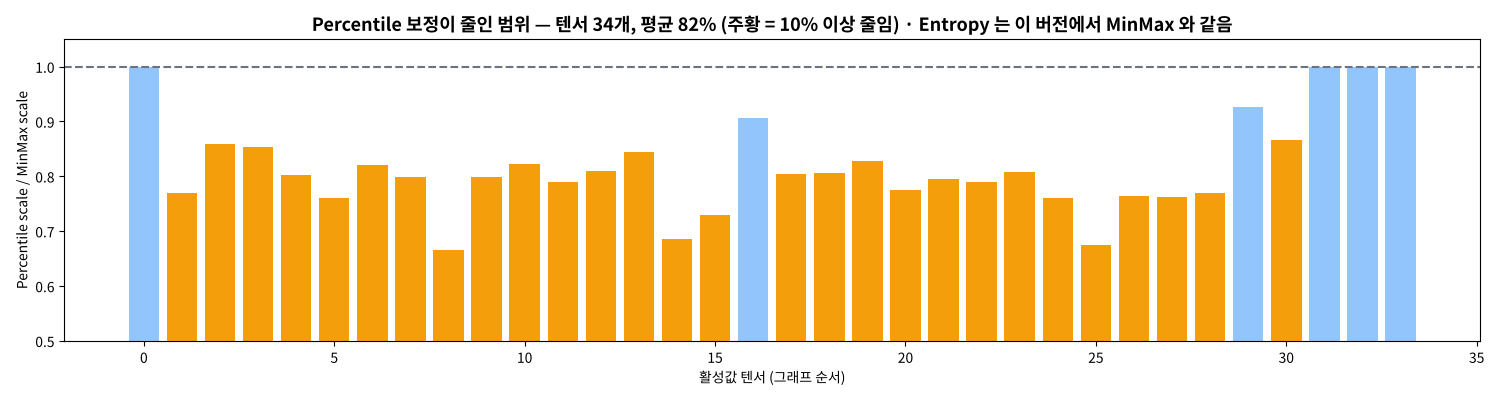

In [ ]:
#@title 🖼 그림 — 실측 — Percentile 이 활성값 34개의 범위를 얼마나 줄였나
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day2/img/f6_scales.png", embed=True, width=860))

#### 📌 6교시 정리

- calibrate_method = Day 1 의 clipping 선택. Percentile 은 드문 큰 값을 잘라 범위를 줄인다.
- 양자화에 강한 모델은 방법 차이가 작다 (0.25%p). 차이가 큰 모델은 Day 3 에서.
- 정확도만 보지 말고 **실제로 고른 scale** 도 열어 본다 — 같은 이름의 방법이 같은 결과를 내는지 확인.

## 7교시 — 성능 측정: 크기 · 정확도 · 지연 시간 · qp_baseline.csv

오늘 만든 모델들을 **같은 조건**으로 재서 한 표에 모읍니다. OT 과정의 `ot_baseline.csv` 처럼, 이 과목은 `qp_baseline.csv` 에 행을 쌓아 Day 6 까지 비교합니다.

> 🎬 **애니메이션** [D2-7 성능 측정과 qp_baseline](https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/animation.html#d2-7)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

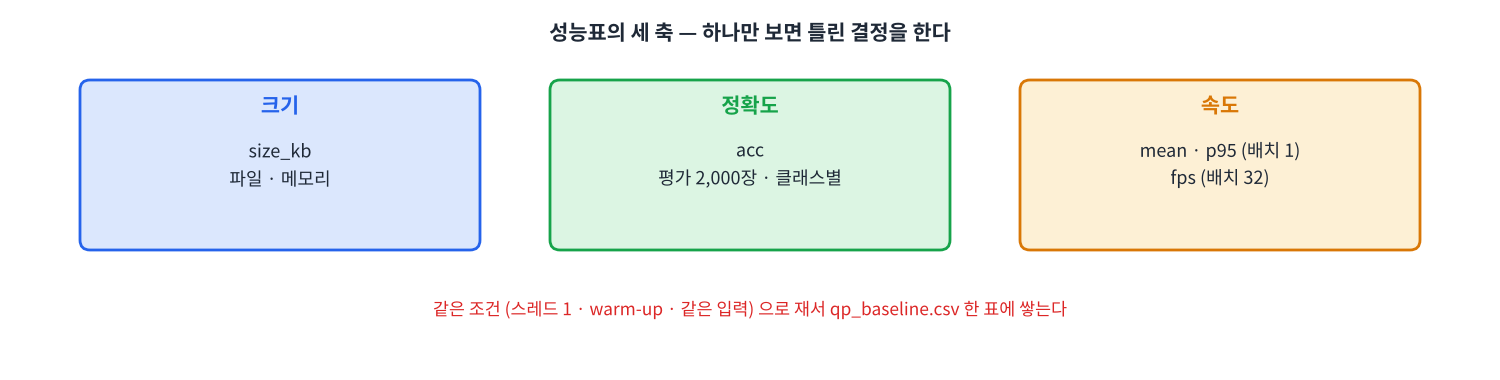

In [ ]:
#@title 🖼 그림 — 크기 · 정확도 · 속도 — 같은 조건으로 재서 한 표에
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day2/img/f7_tradeoff.png", embed=True, width=860))

**✍️ 직접 구현 7-1** 5개 모델의 성능표 `perf_df` 를 만드세요. 열: `model`, `quant`, `size_kb`, `acc`, `mean_ms` (배치 1), `p95_ms` (배치 1), `fps_b32` (배치 32 처리량). 스레드는 1개로 고정합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 7-1 — 실행할 때마다 하나씩
show_hint("7-1", "66qo642466eI64ukIGBtYWtlX3Nlc3Npb24ocGF0aClgIOyEuOyFmCDtlZjrgpjroZwg67Cw7LmYIDEgKGBuPTIwMCwgd2FybT0yMGApIOqzvCDrsLDsuZggMzIgKGBuPTMwLCB3YXJtPTVgKSDrpbwgYmVuY2guHu2WiSDsgqzsoIQg7YKkOiBtb2RlbCDCtyBxdWFudCDCtyBzaXplX2tiIMK3IGFjYyDCtyBtZWFuX21zIMK3IHA5NV9tcyDCtyBmcHNfYjMyICjsl7Qg7Iic7ISc64+EIOydtOuMgOuhnCkuHuyIq+yekOuKlCBgcm91bmQoLi4uLCAzKWAg7KCV64+E66GcIOuLpOuTrOycvOuptCDtkZzqsIAg7J296riwIOyJveyKteuLiOuLpC4=")

In [ ]:
# ✍️ 직접 구현 7-1 — 5개 모델 성능표
MODELS = [("rn20.onnx", "FP32"), ("rn20_dyn.onnx", "dynamic"), ("rn20_int8.onnx", "QDQ U8/S8"),
          ("rn20_s8.onnx", "QDQ S8/S8"), ("rn20_qop.onnx", "QOperator U8/S8")]
perf_df = None    # TODO

display(perf_df)

In [ ]:
assert list(perf_df.columns) == ["model", "quant", "size_kb", "acc", "mean_ms", "p95_ms", "fps_b32"] and len(perf_df) == 5
assert (perf_df.p95_ms >= perf_df.mean_ms * 0.5).all() and perf_df.loc[0, "acc"] == fp32_acc; print("✅ 성능표 완성")

In [ ]:
#@title 🔒 정답 보기 7-1 — 강사가 알려 준 실습 7-1 잠금 코드를 입력하세요
show_answer("7-1", (
    "6Y5IpczFZA6b0K2I2QXQVd1ZCv0hnlsLdCiA+Dd+DQGOAGof5CvJQu2FTrhtGT+J4aMY2HtrWBimjfm17FvHD5fx"
    "WisPkYlYBpJe8krw7Lqm6GGRoNZ1P0SXJ9Xu7ttm39J50CibleTI2u5IpokJyiilTuf+AGA8uxNLs7sOZFpHoUwK"
    "10IceMHq/9UTrDmb+lo4+CBlnaiK5ibqY4YrUH2Sj30zlRi3UQmvgLQ9rFy2agY7FadfyHJDL1+o+27x9HcEtGjT"
    "BY1d1OFGEkeHUuHhVOpriRsh9TVR2rGBFhOciVOOy9e1P3oSJ7XBPO8J/69uvHPiCA9t3ch6LYp5Igd+it3jeaaE"
    "akPMI59oVB+71yyHkCR9Y2nRJn0C5GREqyXWTW2XpWTKS6EdD3BalRohM2RTofI5/Kl1pOhmVgK1l9dO1FabLCZK"
    "zL8scbBUvgXjp5JUUPUxGGN+2MXnY9CGS1LOtE36KQArm0SWtrPU1zzY64X0vQgL5dpq0lIihTpLI3WEF3Y9YHC2"
    "F/Fi2BTcJcVodnl2p2X1TljLi0jt6Iw1+1efDxPtxZi/ItTT6S5yBIro09blNnK7dgNVURhg72QpbGbjeqvcCctO"
    "MQkacqNcxxcIQW4wnLI3Hyz/cU7DiYHeCq7oBQFnu/GsvcSEks2F0P/9vT5D68aviYQbPDbZA5i+2X3k75jpPzZI"
    "RfHojyj28nckxU3cmcYS7wtCcmokbdMtmU89oBvqVat489tCtnQ4bY5luHkBeR4sL+9rdofd+PsN+NUPG3X4wH/z"
    "VatU2v0OHJMQZywAv/JXnYI2bIbezv0SlAl++ozGDGpM0sprGZ68wsRcxUQezdo7uKUk+goUQW2U44vtNHA0Iosx"
    "OoMlNMToObyclYY2ZJsFuFOVLNvIAWU/XCfnwHD4tSWbUy/0WkqeB3LzIa5U/+r/VOARRKCR6rIOytmXU/qeVymo"
    "e+QpZ+N6XjElbtPLeXjJ/zVyGOc3TgCycguABM04pAiVAvqk6kMakNGIuggf4lkqvwP1zl/eLBb5V26MCHCC/F/M"
    "OfU0AbbZht8feqhdze9leRnbOc8UOfcRbGiuUvfy5nnZqORGHsXb/hpuVyyiIhKYHcDb2zVWogeQyzL19ajLxSZ8"
    "pPkjfwcdQL0TTw7ywW6g6S4/h1HRhWRjCbsQCHMuAyhJFdYVjkE3uJS+rl9J52T96eZqZ4t+SyPncTLx6e3wN1Qs"
    "gY/Iq2kjvZ/RxN3ITqwYaYZdEn8UgMg4mmRVjVU6cOGSGAOeRIBPOxQc081GjlHAqRkY7A=="
))


**✍️ 직접 구현 7-2** `perf_df` 를 `qp_baseline.csv` 로 저장하세요 (`index=False`). 앞에 `day` 열(값 `"Day2"`)을 붙이고, 파일이 이미 있으면 **아래에 이어 붙입니다** (Day 3 부터 계속 쌓기 위해).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 7-2 — 실행할 때마다 하나씩
show_hint("7-2", "YG91dCA9IHBlcmZfZGYuY29weSgpYCDtm4QgYG91dC5pbnNlcnQoMCwgImRheSIsICJEYXkyIilgLh7tjIzsnbzsnbQg7J6I7Jy866m0IGBwZC5jb25jYXQoW+q4sOyhtCwgb3V0XSlgIO2bhCBgZHJvcF9kdXBsaWNhdGVzKHN1YnNldD1bImRheSIsICJtb2RlbCJdLCBrZWVwPSJsYXN0IilgLh5gdG9fY3N2KCJxcF9iYXNlbGluZS5jc3YiLCBpbmRleD1GYWxzZSlgLg==")

In [ ]:
# ✍️ 직접 구현 7-2 — qp_baseline.csv 에 쌓기
# TODO
base = pd.read_csv("qp_baseline.csv")
display(base.tail(5))

In [ ]:
assert list(base.columns)[:2] == ["day", "model"] and (base.day == "Day2").sum() == 5; print("✅ qp_baseline.csv 저장 —", len(base), "행")

In [ ]:
#@title 🔒 정답 보기 7-2 — 강사가 알려 준 실습 7-2 잠금 코드를 입력하세요
show_answer("7-2", (
    "6LCPIJxv+Lo2Kh6lKIKMwZ8QgfJ/lYEYVH29jdrXCEd1P1bsF5nwQY56JSMBNYfKAt7Z4eYYZxLBgOi+gROXUA0k"
    "S6BsK4LLt2k9oJAsQS1O23Z8Ijm+hQ+X6HI2mP2PoPQtoSJu6NKpWx3e7s4MZU8j8R2rnQL6DOkZIjZMmz+yJ/sk"
    "Rm1fDQX1ig+izqY4VfXEQyMFepgrJXRFkK4H+3dpjA2vhH/HbWLBzJp5NCikOc9EpjqXO3GtLjYRtEtpPJQMhRF6"
    "vgpB3Ama/ZkaDRA2nCzoiGWl8v+wnGWMtHesLtyCrEidaGtWsqVeqy+XkoQcazE3aX6YSL4zQOGL720Z+aBTDRQb"
    "vqn7ZoSrE6JgrGtZt+vGPEGTbNTdE/zh1KfXyOeiStQVU8a4Pu3jvFkL/8o+hO7cDDQLqUMiBa/vcik/rsNkK50+"
    "vQhkwMM8ZM+eMK8U6XNBdMrdIzIVWakQx2IS0W5O1QLn9nXrHIzCyoXMdzgua1Wv5q9u8huWhnWD0bpF0NOYXC3P"
    "0TB1SvLVj6BKayR8YtWd2dZLnUqbZTb6cCmrnjyN3A9vGl9JGCsEOm+ruMqqY7IkpA88eQz6Y2Acet3314qRiQO0"
    "iwE9971DZYbLLyqhEZBKVkCP+AMYWKpzaJtSbh1QW/8gzLOBGKy27c+P12sdgjEyGzltRCkJ/w993tjeqeXQfQra"
    "BUDSwpmEyAGVCm6n3fG7DCZVNwDRiIB2MsoLKmfh4EsQ0nSE8I32SAuzVNSRAn1/cwb1TbrfuAzuJeHpjW8/Vi8K"
    "ro1f6KqUycckq6uYI4v939oEM8y++1xiG+z984DrrxYIR4bZDrcLRsZKqcgM5D0nhTg8CF2W2ZwY3AnsFwXYM0iZ"
    "6rDaFchbTIEjFuxeOfWnlz+DVigFK//lzbTIAnUeNUaY4PlmnwykXEU="
))


In [ ]:
# 🔁 바꿔보기 — 정확도 vs 속도 그림 (오른쪽 위가 좋은 모델)
plt.figure(figsize=(7, 4))
for r in perf_df.itertuples():
    plt.scatter(r.fps_b32, r.acc * 100, s=r.size_kb / 3)
    plt.annotate(r.quant, (r.fps_b32, r.acc * 100), textcoords="offset points", xytext=(6, 4), fontsize=9)
plt.xlabel("throughput (img/s, batch 32, 1 thread)"); plt.ylabel("accuracy (%)"); plt.title("size = marker area")
plt.grid(alpha=.3); plt.show()

#### 📌 7교시 정리

- 비교는 **같은 조건** (스레드 1 · 같은 입력 · warm-up) 으로. 지연 시간(배치 1)과 처리량(배치 32)을 따로.
- 이 컴퓨터에서 static INT8 (U8/S8) 은 크기 약 1/3 · 처리량 약 2배 · 정확도 손실 거의 없음. dynamic 은 오히려 느림.
- 결과는 `qp_baseline.csv` 에 쌓는다 — Day 3 이후 TensorRT INT8 · QAT · Pruning 행이 이어진다.

## 8교시 — 미니 프로젝트: 최적 PTQ 설정 찾기 · 채점

**과제** — ResNet-20 을 현장 PC(x86 CPU)에 배포합니다. **정확도 손실 1%p 이내**에서 **배치 1 지연 시간이 가장 짧은** PTQ 설정을 찾아 `rn20_best.onnx` 로 저장하세요.

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | `make_ptq(fmt, act, method, pc)` — 설정 하나로 INT8 모델 만들기 | 20 |
| 2 | `evaluate(path)` — 정확도 · 크기 · 지연 시간 | 20 |
| 3 | 16가지 조합 그리드 실행 → `grid_df` | 20 |
| 4 | 규칙대로 선택 → `rn20_best.onnx` · `qp_baseline.csv` 에 추가 | 20 |
| 5 | 클래스별 정확도 비교 — 특정 클래스만 나빠지지 않았나 | 10 |
| 6 | 결과 해석 (마크다운 답변) | 10 |

> 미니 프로젝트에는 **정답 보기 셀이 없습니다.** 힌트만 보고 완성하세요. 정답 노트북은 제출 마감 뒤 공개합니다. 채점 셀을 실행하면 자동 채점 점수와 **정답 열람 기록**이 나옵니다(과제 6 은 강사 채점).

> 🎬 **애니메이션** [D2-8 PTQ 설정 탐색](https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/animation.html#d2-8)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

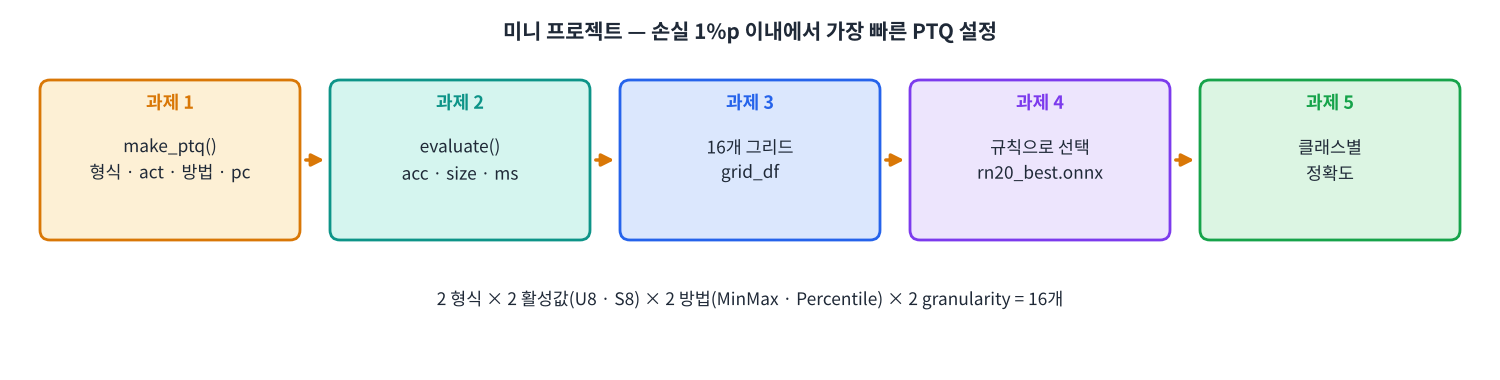

In [ ]:
#@title 🖼 그림 — 미니 프로젝트 흐름 — 설정 16개를 만들고, 재고, 규칙으로 고른다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day2/img/f8_project.png", embed=True, width=860))

**과제 1 (20점)** `make_ptq(fmt, act, method, pc)` 를 완성하세요. 인자는 `"QDQ"`/`"QOperator"`, `"U8"`/`"S8"`, `"MinMax"`/`"Percentile"`, `True`/`False`. 파일 이름 `pj_{fmt}_{act}_{method}_{pc|pt}.onnx` 로 저장하고 경로를 돌려줍니다. weight 는 항상 S8, 입력은 `rn20_pre.onnx`.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 8-1 — 실행할 때마다 하나씩
show_hint("8-1", "66y47J6Q7Je0IOKGkiBPUlQg7IOB7IiYIOyCrOyghCAz6rCc66W8IOunjOuTreuLiOuLpDog7ZiV7IudKFFEUSDCtyBRT3BlcmF0b3IpLCDtmZzshLHqsJIoVTggwrcgUzgpLCDrsKnrspUoTWluTWF4IMK3IFBlcmNlbnRpbGUpLh7tjIzsnbwg7J2066aEIGBmInBqX3tmbXR9X3thY3R9X3ttZXRob2R9X3sncGMnIGlmIHBjIGVsc2UgJ3B0J30ub25ueCJgLh53ZWlnaHRfdHlwZSDsnYAg7ZWt7IOBIGBRdWFudFR5cGUuUUludDhgLCDsnoXroKXsnYAgYHJuMjBfcHJlLm9ubnhgLCByZWFkZXIg64qUIOunpOuyiCDsg4ggYENpZmFyUmVhZGVyKFhfY2FsKWAu")

In [ ]:
# ✍️ 과제 1 — 설정 하나로 INT8 모델 만들기
def make_ptq(fmt, act, method, pc):
    # TODO: 경로 돌려주기
    pass

p_test = make_ptq("QOperator", "U8", "MinMax", True)
print(p_test, op_count(p_test).most_common(3))

**과제 2 (20점)** `evaluate(path)` 가 `{"acc", "size_kb", "mean_ms", "p95_ms"}` 사전을 돌려주게 완성하세요. 지연 시간은 스레드 1 · 배치 1 · `n=100, warm=10`.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 8-2 — 실행할 때마다 하나씩
show_hint("8-2", "MSDCtyAy6rWQ7IucIOuPhOq1rOulvCDrrLbsirXri4jri6Q6IGBvcnRfYWNjYCwgYHNpemVfa2JgLCBgYmVuY2gobWFrZV9zZXNzaW9uKHBhdGgpLCBYX2V2WzoxXSwgbj0xMDAsIHdhcm09MTApYC4e64+M66Ck7KSEIO2CpDogYWNjIMK3IHNpemVfa2IgwrcgbWVhbl9tcyDCtyBwOTVfbXMu")

In [ ]:
# ✍️ 과제 2 — 모델 하나 평가
def evaluate(path):
    # TODO
    pass

print(evaluate(p_test))

**과제 3 (20점)** 16가지 조합 (형식 2 × 활성값 2 × 방법 2 × per-channel 2) 을 모두 만들고 평가해 `grid_df` 를 만드세요. 열: `fmt`, `act`, `method`, `per_channel`, `path`, `acc`, `size_kb`, `mean_ms`, `p95_ms`. (약 2분 걸립니다)

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 8-3 — 실행할 때마다 하나씩
show_hint("8-3", "YGl0ZXJ0b29scy5wcm9kdWN0KFsiUURRIiwgIlFPcGVyYXRvciJdLCBbIlU4IiwgIlM4Il0sIFsiTWluTWF4IiwgIlBlcmNlbnRpbGUiXSwgW0ZhbHNlLCBUcnVlXSlgIOuhnCAxNuqwnCDsobDtlakuHuyhsO2VqeuniOuLpCBgcGF0aCA9IG1ha2VfcHRxKC4uLilgIOKGkiBgZXZhbHVhdGUocGF0aClgLh7tlokg7IKs7KCEOiBgeyJmbXQiOiAuLi4sICJhY3QiOiAuLi4sICJtZXRob2QiOiAuLi4sICJwZXJfY2hhbm5lbCI6IC4uLiwgInBhdGgiOiBwYXRoLCAqKmV2YWx1YXRlKHBhdGgpfWAu")

In [ ]:
# ✍️ 과제 3 — 16가지 조합 그리드 (약 2분)
import itertools
grid_df = None    # TODO

display(grid_df.sort_values("mean_ms").round(4))

**과제 4 (20점)** `fp32_acc − 0.01` 이상인 조합 중 `mean_ms` 가 가장 작은 행을 `best` 로 고르고, 그 파일을 `rn20_best.onnx` 로 복사하세요. 그리고 7-2 처럼 `qp_baseline.csv` 에 `day="Day2"`, `model="rn20_best.onnx"` 행을 추가합니다 (`quant` 는 `"{fmt} {act}/S8 {method} {pc|pt}"`).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 8-4 — 실행할 때마다 하나씩
show_hint("8-4", "7KGw6rG0OiBgZ3JpZF9kZi5hY2MgPj0gZnAzMl9hY2MgLSAwLjAxIC0gMWUtOWAg66GcIOqxsOuluCDrkqQgYHNvcnRfdmFsdWVzKCJtZWFuX21zIikuaWxvY1swXWAuHmBzaHV0aWwuY29weShiZXN0LnBhdGgsICJybjIwX2Jlc3Qub25ueCIpYC4ecXBfYmFzZWxpbmUuY3N2IO2WiTogZGF5IMK3IG1vZGVsIMK3IHF1YW50IMK3IHNpemVfa2IgwrcgYWNjIMK3IG1lYW5fbXMgwrcgcDk1X21zIMK3IGZwc19iMzIgKGZwc19iMzIg64qUIOuwsOy5mCAzMiDroZwgYmVuY2gpLh43LTIg7LKY65+8IGNvbmNhdCDtm4QgKGRheSwgbW9kZWwpIOykkeuztSDsoJzqsbDtlZjqs6Ag7KCA7J6lLg==")

In [ ]:
# ✍️ 과제 4 — 규칙대로 선택하고 저장
best = None       # TODO: 선택된 행 (Series)
# TODO: rn20_best.onnx 로 복사, qp_baseline.csv 에 행 추가

print("선택:", best.fmt, best.act, best.method, best.per_channel, f"| 정확도 {best.acc:.4f} | {best.mean_ms:.3f} ms")

**과제 5 (10점)** FP32 (`rn20.onnx`) 와 `rn20_best.onnx` 의 **클래스별 정확도** 배열 `cls_fp32`, `cls_best` (길이 10) 를 구하고, 가장 많이 떨어진 클래스 `worst_cls` (이름) 와 그 하락 폭 `worst_drop` (%p) 을 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 8-5 — 실행할 때마다 하나씩
show_hint("8-5", "7JiI7Lih7J2EIOuqqOydgCDrkqQg7YG0656Y7IqkIGsg66eI64ukIGAocHJlZFt5X2V2ID09IGtdID09IGspLm1lYW4oKWAg4oaSIOq4uOydtCAxMCDrsLDsl7QuHu2VmOudvSA9IGNsc19mcDMyIOKIkiBjbHNfYmVzdC4g6rCA7J6lIO2BsCDtlZjrnb3snZgg7JyE7LmYID0gYG5wLmFyZ21heCguLi4pYC4e7J2066aE7J2AIGBDTEFTU0VTW2tdYCwg7ZWY6529IO2PreydgCDDlyAxMDAgKCVwKS4=")

In [ ]:
# ✍️ 과제 5 — 클래스별 정확도 비교
def class_acc(path):
    # TODO: 길이 10 numpy 배열
    pass

cls_fp32, cls_best = class_acc("rn20.onnx"), class_acc("rn20_best.onnx")
worst_cls, worst_drop = None, None   # TODO
display(pd.DataFrame({"class": CLASSES, "FP32": cls_fp32, "best": cls_best, "diff(%p)": (cls_best - cls_fp32) * 100}).round(3))
print(f"가장 많이 떨어진 클래스: {worst_cls} ({worst_drop:.1f}%p 하락)")

### 과제 6 — 결과 해석 (10점)

아래 셀에 답을 쓰세요.

1. 선택된 설정의 형식(QDQ / QOperator)과 활성값 자료형(U8 / S8)이 왜 빨랐는지, 5교시 결과로 설명하세요.
2. 16개 조합의 정확도 차이는 몇 %p 였나요? 평가 2,000장에서 1장이 0.05%p 라는 점을 생각하면 이 차이를 믿을 수 있나요?
3. 이 결과를 그대로 Jetson(ARM CPU · TensorRT)에 가져가도 될까요? 무엇을 다시 재야 하나요?
4. 현장 카메라가 밤에도 쓰인다면 보정 데이터를 어떻게 준비해야 할까요? (예제 4-B 결과 참고)

✍️ *여기에 답을 쓰세요.*

### 채점 셀

In [ ]:
score = 0
try:
    p = make_ptq("QDQ", "S8", "Percentile", False)
    gq = onnx.load(p).graph; iq = {i.name: numpy_helper.to_array(i) for i in gq.initializer}
    zq = [iq[n.input[2]] for n in gq.node if n.op_type == "QuantizeLinear"]
    assert p == "pj_QDQ_S8_Percentile_pt.onnx" and zq and all(z.dtype == np.int8 for z in zq)
    assert op_count(make_ptq("QOperator", "U8", "MinMax", True))["QLinearConv"] == 21
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", repr(e))
try:
    e1 = evaluate("rn20_int8.onnx")
    assert set(e1) == {"acc", "size_kb", "mean_ms", "p95_ms"} and e1["acc"] == ort_acc("rn20_int8.onnx") and abs(e1["size_kb"] - size_kb("rn20_int8.onnx")) < 1e-6 and e1["mean_ms"] > 0
    score += 20; print("✅ 과제 2  +20")
except Exception as e: print("❌ 과제 2", repr(e))
try:
    assert len(grid_df) == 16 and {"fmt", "act", "method", "per_channel", "path", "acc", "size_kb", "mean_ms", "p95_ms"} <= set(grid_df.columns)
    assert grid_df.groupby(["fmt", "act", "method", "per_channel"]).size().max() == 1 and all(os.path.exists(x) for x in grid_df.path)
    score += 20; print("✅ 과제 3  +20")
except Exception as e: print("❌ 과제 3", repr(e))
try:
    exp_best = grid_df[grid_df.acc >= fp32_acc - 0.01 - 1e-9].sort_values("mean_ms").iloc[0]
    bb = pd.read_csv("qp_baseline.csv")
    assert best.path == exp_best.path and ort_acc("rn20_best.onnx") == exp_best.acc
    assert ((bb.day == "Day2") & (bb.model == "rn20_best.onnx")).sum() == 1
    score += 20; print("✅ 과제 4  +20")
except Exception as e: print("❌ 과제 4", repr(e))
try:
    assert cls_fp32.shape == (10,) and np.allclose(cls_fp32.mean(), fp32_acc) and worst_cls == CLASSES[int(np.argmax(cls_fp32 - cls_best))]
    assert abs(worst_drop - (cls_fp32 - cls_best).max() * 100) < 1e-6
    score += 10; print("✅ 과제 5  +10")
except Exception as e: print("❌ 과제 5", repr(e))
print(f"\n자동 채점 {score} / 90  (+ 과제 6 강사 채점 10점)")
seen = [l.split("\t")[0] for l in open(".qp_answer_log")] if os.path.exists(".qp_answer_log") else []
seen = list(dict.fromkeys(seen))
print(f"정답 열람 {len(seen)}개" + (f" — {', '.join(seen)}" if seen else " — 없음 👍"))

#### 📌 8교시 정리

- PTQ 설정은 **형식 · 활성값 자료형 · 보정 방법 · granularity** 4가지. 규칙(손실 한도 → 속도)을 먼저 정하고 그리드로 고른다.
- 지연 시간은 측정할 때마다 흔들린다 → 결정은 여유를 두고, 배포 장치에서 다시 잰다.
- 전체 정확도와 함께 **클래스별 정확도**도 본다.

## 오늘의 정리

### 셀프 체크

- [ ] dynamic 과 static PTQ 의 차이, CNN 에서 dynamic 이 느린 이유를 노드 구성으로 설명할 수 있다
- [ ] BN folding 식을 쓰고, PyTorch exporter 가 이미 folding 한다는 것을 확인했다
- [ ] `quant_pre_process` 가 하는 일을 말할 수 있다
- [ ] `CalibrationDataReader` 를 직접 작성할 수 있다
- [ ] ONNX 파일의 scale · zp 를 꺼내 `my_quant.py` 로 검산했다
- [ ] 보정 데이터의 분포가 틀리면 정확도가 크게 떨어진다는 것을 실험으로 보였다
- [ ] QDQ 와 QOperator, U8 / S8 의 차이를 그래프와 속도로 비교했다
- [ ] 3가지 보정 방법이 고른 scale 을 비교하고, 결과를 `qp_baseline.csv` 에 기록했다

### 내일 (Day 3) 예고

ResNet-20 은 양자화에 강했습니다. 내일은 **정확도가 크게 떨어지는 모델**을 일부러 만들어, layer 별 오차를 재서 범인을 찾고 그 layer 만 FP32 로 남기는 **mixed precision** 으로 고칩니다. 그리고 오늘 만든 **QDQ 모델을 TensorRT INT8 엔진**으로 바꿔 GPU 에서 실행합니다.

## 📝 Day 2 복습 퀴즈 — 수업이 끝난 뒤

오늘 배운 1~8교시 내용을 **24문항**으로 점검합니다. 9가지 유형이 섞여 있습니다.

👉 **[Day 2 복습 퀴즈 열기](https://imguru-mooc.github.io/AI_CAMPUS/QP-day2/review_quiz.html)**

1. 이름을 입력하고 24문항을 모두 풉니다.
2. **채점하기** → 정오와 해설이 나타납니다. 채점 후에는 답이 잠깁니다.
3. **제출 (오답 정리)** → 점수 · 결과 코드 · 오답 정리를 **텍스트 복사** 또는 캡처로 강사가 안내한 곳에 제출합니다.